# Growing the pie: where Chow's lead expanded, 2023 → 2026

This notebook supports the "Growing the pie" section of the blog post. It answers three questions:

1. **Where did Chow gain a lead**, and how much of her additional vote came from areas she already led, newly led, or still trailed?
2. **How did the demographic relationships** with her vote, and with her main opponent's vote, change between 2023 and 2026?
3. **What distinguished the newly leading tracts**, and did the kinds of places supplying her votes change much overall?

**Coverage note (applies to every figure).** The tract estimates cover **mapped poll votes**: the votes the City reports for polling subdivisions with a map polygon, spread over 2021 census tracts. They are about **78% of valid votes in 2023 and 76% in 2026**. The omitted ballots matter most for the 2023 baseline: Chow led the official 2023 result (37.2% to 32.5%) but *trailed* Bailão in the mapped subset (34.4% to 37.6%). "Newly leading" therefore means newly leading in mapped votes. Everything below describes **neighbourhoods and mapped votes**: census data (2021) describe residents and households, not voters, and the same census data apply to both elections.

In [1]:
import json
import re
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
REPO_ROOT = Path.cwd().resolve().parents[1]
ELECTION_DIR = REPO_ROOT / "data" / "election_results"
CLEAN_DIR = ELECTION_DIR / "2026-results-clean"
MAYOR_GPKG = CLEAN_DIR / "mayor_2023_2026_ct.gpkg"
COUNCIL_GPKG = CLEAN_DIR / "councillor_2026_ct.gpkg"       # only its `wards` layer is used (outlines and names for orientation)
RAW_DIR = ELECTION_DIR / "2026-results-raw"
MAYOR_XLSX = RAW_DIR / "Poll_By_Poll_Mayor.xlsx"
ARCHIVE_2023 = (REPO_ROOT / "analysis" / "toronto_election_turnout" / "data" / "archive" / "elections"
                / "processed" / "municipal_2023_mayor")
CENSUS_META = REPO_ROOT / "src" / "routes" / "social-geography-and-the-mayoral-vote" / "data" / "meta.json"
SOCGEO_DIR = REPO_ROOT / "src" / "routes" / "social-geography-and-the-mayoral-vote" / "data"
ELECTIONS_PARQUET = SOCGEO_DIR / "elections.parquet"      # tract-level mayoral results, 1997-2026, on 2021 tracts
CENSUS_PARQUET = SOCGEO_DIR / "census.parquet"            # census variables by tract for 1996-2021, on 2021 tracts

PROJECTED_EPSG = 32617                    # UTM 17N (metres), maps only
SPECIAL_BUCKETS = (97, 98, 99)            # 2026 poll-by-poll subdivisions with no polygon
MAPPED_2023_TYPES = ("election_day", "special")
CANDIDATES = {2023: {"chow": "Chow Olivia", "opp": "Bailão Ana"}, 2026: {"chow": "Chow Olivia", "opp": "Bradford Brad"}}
OPP_SLUG = {2023: "bailao_ana", 2026: "bradford_brad"}

MIN_VALID_VOTES = 300                     # "small tract": fewer valid votes than this in either election
NEAR_TIE_PP = 2                           # near-tie buffer: |Chow minus opponent margin| below this many points in either election

# Transition groups: who led the head-to-head contest in each election (Chow vs. Bailão 2023, Chow vs. Bradford 2026)
MAIN = ["Established support", "Newly leading", "Persistent opposition lead"]
SMALL = ["Reverse transition", "Exact tie"]
GROUPS = MAIN + SMALL
GROUP_COLOURS = {"Established support": "#54278f", "Newly leading": "#f28e2b", "Persistent opposition lead": "#238b45",   # three prominent colours
                 "Reverse transition": "#9ecae1", "Exact tie": "#cfcfcf"}                                                     # muted
CHOW, OPP, OTHER, C23 = "#54278f", "#238b45", "#b5b5b5", "#8c8c8c"   # candidate colours: Chow deep purple, main opponent green
LABEL_WARDS = [23, 18, 15, 2, 13, 19, 5]  # a few wards named on maps for orientation
FOOTNOTE = "Mapped poll votes only (about 78% of valid votes in 2023, 76% in 2026). Neighbourhood-level estimates."

FORMER_MUNI = REPO_ROOT / "src" / "routes" / "the-2026-mayoral-election-local-landslides" / "data" / "former_municipalities.geo.json"   # six pre-1998 municipalities, as used elsewhere on the site
# Concentration contrasts (Section 4): variable -> (low group: at most this, high group: at least this), in % of the variable's own universe; income is a tract percentile
CONTRAST = {"hhtnrent_pct": (30, 70), "jwmdtran_pct": (20, 35), "vminvisi_pct": (30, 70), "income_pct": (20, 80), "dwtpsdet_pct": (10, 50), "jwmdauto_pct": (45, 75),
            "walkbike": (3, 15), "imstimmi_pct": (35, 60), "edcauniv_pct": (25, 50), "agec2029_pct": (10, 20), "agec065p_pct": (10, 25)}
FOCUS_VARS = ["hhtnrent_pct", "jwmdtran_pct", "vminvisi_pct", "income_pct"]    # the four contrasts shown in detail
MIN_GROUP_TRACTS = 15                     # contrasts with fewer tracts in either group are not reported
BOOT_REPS, SEED = 2000, 2026              # ward-cluster bootstrap for the gaps
BAND_EDGES = [0, 20, 30, 40, 50, 101]       # bands of Chow's 2023 tract share of all valid mapped votes (%)
BAND_LABELS = ["Under 20%", "20-30%", "30-40%", "40-50%", "50% or more"]
CHOW_2014_LIGHT = "#b7a3d6"               # Chow 2014 (2011 census) in the correlation figures

# Census variables: column -> (label, unit, scale for display)
CENSUS = {
    "hhtnrent_pct": ("Renter households", "% of households", 100), "dwtpsdet_pct": ("Single-detached dwellings", "% of dwellings", 100),
    "ihat_med__nc": ("Median household income", "dollars", 1), "agec2029_pct": ("Age 20-29", "% of residents", 100),
    "agec065p_pct": ("Age 65+", "% of residents", 100), "jwmdauto_pct": ("Commute by car", "% of commuters", 100),
    "jwmdtran_pct": ("Commute by transit", "% of commuters", 100), "walkbike": ("Commute by walking or cycling", "% of commuters", 100),
    "vminvisi_pct": ("Visible minority", "% of residents", 100), "imstimmi_pct": ("Immigrants", "% of residents", 100),
    "popdsqkm__nc": ("Population density", "people per km²", 1), "edcauniv_pct": ("University degree", "% of adults", 100),
}
CORR_VARS = ["hhtnrent_pct", "dwtpsdet_pct", "ihat_med__nc", "agec2029_pct", "agec065p_pct", "jwmdauto_pct", "jwmdtran_pct", "walkbike", "vminvisi_pct", "imstimmi_pct", "popdsqkm__nc"]
PAIRED_VARS = ["hhtnrent_pct", "jwmdauto_pct", "walkbike", "ihat_med__nc", "imstimmi_pct", "vminvisi_pct"]   # variables for the paired-dot chart
PROFILE_VARS = ["hhtnrent_pct", "dwtpsdet_pct", "income_pct", "jwmdauto_pct", "walkbike", "edcauniv_pct"]          # newly-leading profile (income as percentile)
WEIGHTED_VARS = ["hhtnrent_pct", "jwmdauto_pct", "dwtpsdet_pct", "income_pct"]                                    # vote-weighted comparison

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6"})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

## Data and measures

Official all-method totals and mapped totals are rebuilt from the City's source files as a quick reference for the coverage note.

In [3]:
mayor = gpd.read_file(MAYOR_GPKG, layer="mayor_ct")
wards = gpd.read_file(COUNCIL_GPKG, layer="wards")

def parse_poll_by_poll(path):
    '''Long table (ward, sub, candidate, votes) from the City's poll-by-poll workbook (one sheet per ward).'''
    rows = []
    for sheet, x in tqdm(pd.read_excel(path, sheet_name=None, header=None).items(), desc="wards", leave=False):
        ward = int(sheet.split()[1]); subs = x.iloc[1, 1:-1].astype(int).tolist()
        body = x.iloc[3:-1]; body = body[body[0].notna()]
        for name, vals in zip(body[0], body.iloc[:, 1:-1].astype(float).values):
            rows.extend((ward, s, name.strip(), v) for s, v in zip(subs, vals))
    return pd.DataFrame(rows, columns=["ward", "sub", "candidate", "votes"])

src26 = parse_poll_by_poll(MAYOR_XLSX); src26["mapped"] = ~src26["sub"].isin(SPECIAL_BUCKETS)
polls23 = pd.read_csv(ARCHIVE_2023 / "turnout" / "toronto_municipal_2023_mayor_turnout_subdivisions.csv", usecols=["poll_id", "vote_type"])
cand23 = pd.read_csv(ARCHIVE_2023 / "candidate_details" / "toronto_municipal_2023_mayor_candidates.csv").set_index("candidate_id")["candidate_name"]
src23 = pd.read_csv(ARCHIVE_2023 / "candidate_details" / "toronto_municipal_2023_mayor_poll_candidate_votes.csv").merge(polls23, on="poll_id")
src23["candidate"] = src23["candidate_id"].map(cand23); src23["votes"] = src23["candidate_vote_count"]; src23["mapped"] = src23["vote_type"].isin(MAPPED_2023_TYPES)
SRC = {2023: src23, 2026: src26}
rows = []
for y in (2023, 2026):
    d = SRC[y]; n = CANDIDATES[y]
    off = {"chow": d.loc[d.candidate == n["chow"], "votes"].sum(), "opp": d.loc[d.candidate == n["opp"], "votes"].sum(), "valid": d["votes"].sum()}
    lay = {"chow": mayor[f"mayor{y}_chow_olivia_votes"].sum(), "opp": mayor[f"mayor{y}_{OPP_SLUG[y]}_votes"].sum(), "valid": mayor[f"mayor{y}_votes_candidates"].sum()}
    for label, s in (("official, all methods", off), ("tract layer, mapped votes", lay)):
        rows.append({"election": f"{y}: Chow vs. {n['opp'].split()[0]}", "basis": label, "valid votes": s["valid"], "% of official": s["valid"] / off["valid"] * 100,
                     "Chow %": s["chow"] / s["valid"] * 100, "opponent %": s["opp"] / s["valid"] * 100, "Chow margin (pp)": (s["chow"] - s["opp"]) / s["valid"] * 100})
display(pd.DataFrame(rows).set_index(["election", "basis"]).round(1))

valid votes  % of official  Chow %  opponent %  Chow margin (pp)
election                basis                                                                                      
2023: Chow vs. Bailão   official, all methods        724,638.0          100.0    37.2        32.5               4.7
                        tract layer, mapped votes    566,398.0           78.2    34.4        37.6              -3.2
2026: Chow vs. Bradford official, all methods        982,660.0          100.0    54.2        41.1              13.0
                        tract layer, mapped votes    750,008.0           76.3    54.7        40.6              14.1

In [4]:
t = mayor[["ctuid2021", "ward_dominant"]].copy()
for y in (2023, 2026):
    s = str(y)[2:]
    v, c, o = mayor[f"mayor{y}_votes_candidates"], mayor[f"mayor{y}_chow_olivia_votes"], mayor[f"mayor{y}_{OPP_SLUG[y]}_votes"]
    t[f"valid{s}"], t[f"chow_v{s}"], t[f"opp_v{s}"] = v, c, o
    t[f"chow{s}"], t[f"opp{s}"] = c / v * 100, o / v * 100            # shares of ALL valid mapped votes
    t[f"margin{s}"] = t[f"chow{s}"] - t[f"opp{s}"]
    t[f"pair{s}"] = c / (c + o) * 100                                 # Chow's share of the Chow + main-opponent vote
t["d_chow"], t["d_opp"], t["d_pair"] = t.chow26 - t.chow23, t.opp26 - t.opp23, t.pair26 - t.pair23   # d_opp compares two different candidates
t["d_chow_v"] = t.chow_v26 - t.chow_v23
t["big"] = (t.valid23 >= MIN_VALID_VOTES) & (t.valid26 >= MIN_VALID_VOTES)
t = t.merge(mayor.drop(columns=["geometry", "ward_dominant"] + [c for c in mayor.columns if c.startswith("mayor")] + ["area_km2", "ward_dominant_share"]), on="ctuid2021")
t["walkbike"] = t.jwmdwalk_pct + t.jwmdbike_pct                       # walking and cycling share one denominator (commuters)
t["income_pct"] = t.ihat_med__nc.rank(pct=True) * 100                 # income as a tract percentile (0-100)
t = gpd.GeoDataFrame(t, geometry=mayor.geometry.values, crs=mayor.crs)

lead = {s: np.sign(t[f"margin{s}"].round(9)) for s in ("23", "26")}
tie = (lead["23"] == 0) | (lead["26"] == 0)
t["group"] = np.select([tie, (lead["23"] > 0) & (lead["26"] > 0), (lead["23"] < 0) & (lead["26"] > 0), (lead["23"] < 0) & (lead["26"] < 0), (lead["23"] > 0) & (lead["26"] < 0)],
                       ["Exact tie"] + MAIN[:1] + MAIN[1:2] + MAIN[2:] + ["Reverse transition"], "?")
assert (t.group != "?").all() and len(t) == 585
tp = t.to_crs(PROJECTED_EPSG); wp = wards.to_crs(PROJECTED_EPSG)
label_pts = wp[wp["ward"].isin(LABEL_WARDS)].copy(); label_pts["pt"] = label_pts.geometry.representative_point()
print("Tracts per group:", t.group.value_counts().reindex(GROUPS).to_dict())

Tracts per group: {'Established support': 256, 'Newly leading': 146, 'Persistent opposition lead': 177, 'Reverse transition': 2, 'Exact tie': 4}


## 1. Where did Chow gain a lead?

Each tract is classified by who led the **head-to-head contest** in each election (Chow's signed margin over Bailão in 2023 and over Bradford in 2026, above or below zero). The map gives every tract one category regardless of its vote total or the size of its margin. Exact ties (estimated Chow votes equal to the opponent's in an election) are kept apart rather than assigned to a side.

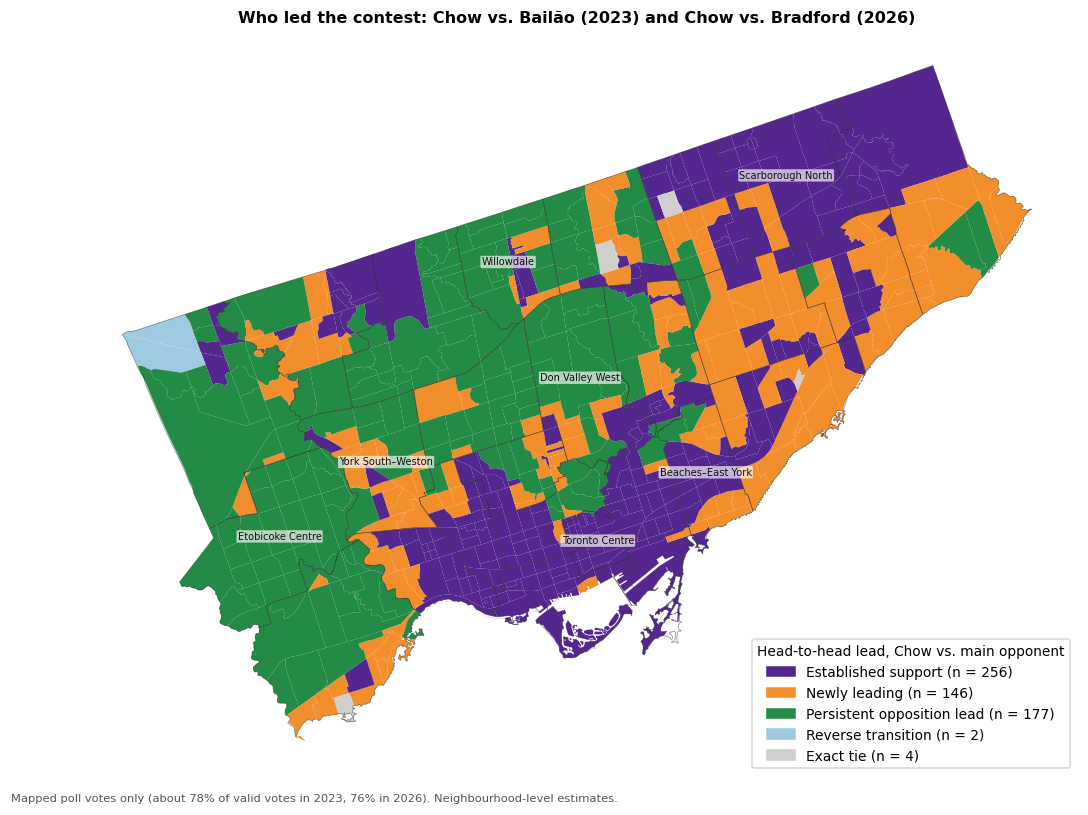

In [5]:
def draw_wards(ax, labels=True):
    wp.boundary.plot(ax=ax, color="#333333", linewidth=.4, alpha=.65)
    if labels:
        for _, r in label_pts.iterrows():
            ax.annotate(r["ward_name"].replace("-", "–"), (r["pt"].x, r["pt"].y), fontsize=6.5, ha="center", color="#111", bbox=dict(boxstyle="round,pad=.12", fc="white", ec="none", alpha=.65))

def foot(fig, y=0.005):
    fig.text(.01, y, FOOTNOTE, fontsize=7.5, color="#555", ha="left", va="bottom")

tp["code"] = pd.Categorical(tp.group, categories=GROUPS).codes
fig, ax = plt.subplots(figsize=(10.5, 7.4))
tp.plot(column="code", cmap=ListedColormap([GROUP_COLOURS[g] for g in GROUPS]), ax=ax, linewidth=0)
draw_wards(ax); ax.set_axis_off()
ax.legend(handles=[Patch(color=GROUP_COLOURS[g], label=f"{g} (n = {int((t.group == g).sum())})") for g in GROUPS], loc="lower right", fontsize=9, frameon=True, title="Head-to-head lead, Chow vs. main opponent", title_fontsize=9)
ax.set_title("Who led the contest: Chow vs. Bailão (2023) and Chow vs. Bradford (2026)", fontsize=10.5)
foot(fig); plt.tight_layout(rect=(0, .02, 1, 1)); plt.show()

**What the map shows.** Chow led in both elections (deep purple) across a compact block around the lakeshore core and east end, and through a strip along the north-east edge. The tracts she newly led (orange) form a broad, irregular middle zone, mostly east of the core and in parts of the west, rather than a ring hugging the established block. Tracts her main opponent led in both elections (green) are a large contiguous area from the western edge through the north-west and into the centre-north. The two reverse transitions and four exact ties are too few to read as patterns. Counts: **256 established, 146 newly leading, 177 persistent opposition, 2 reverse, 4 ties**.

### Change in vote share, and where the added votes were

Left: Chow's **pooled** share of all valid mapped votes (summed votes divided by summed valid votes) in 2023 and 2026 for each of the three main groups, with the percentage-point gain labelled and the citywide figure for reference. Right: her added mapped votes in each group and each group's share of her **citywide net increase** (all 585 tracts form the denominator). The two small groups are included in the right panel and the table.

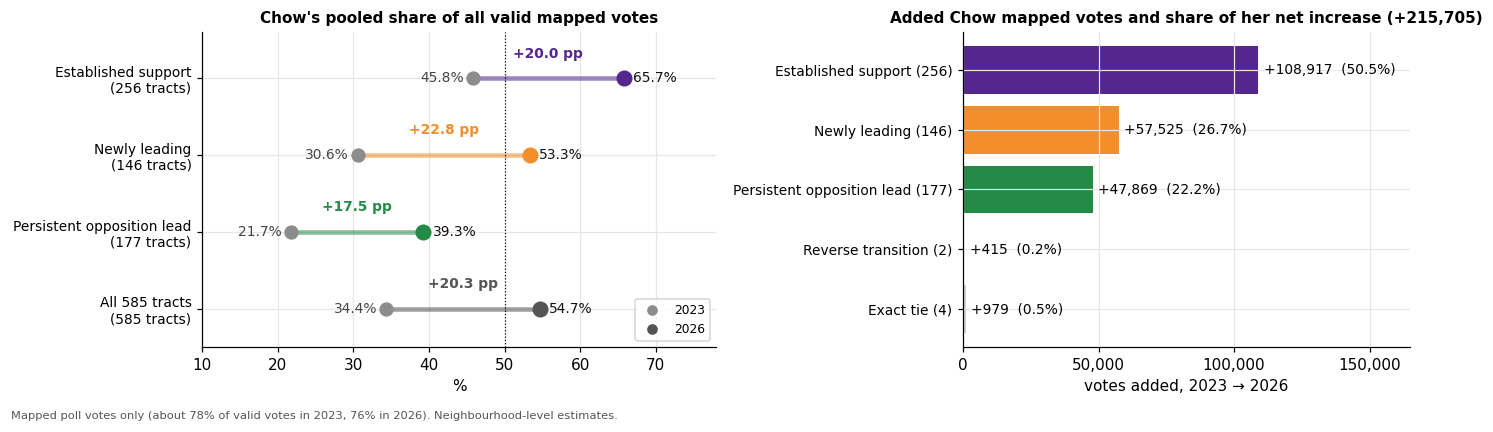

,tracts,Chow % 2023,Chow % 2026,gain (pp),added votes,% of her net increase
Established support,256.0,45.8,65.7,20.0,"108,917.0",50.5
Newly leading,146.0,30.6,53.3,22.8,"57,525.0",26.7
Persistent opposition lead,177.0,21.7,39.3,17.5,"47,869.0",22.2
Reverse transition,2.0,32.0,44.5,12.6,415.0,0.2
Exact tie,4.0,32.4,50.0,17.6,979.0,0.5


Citywide (all 585 tracts, pooled): Chow 34.4% -> 54.7% of valid mapped votes; net increase 215,705 mapped votes. Valid mapped votes grew 32.4% overall.


In [6]:
def pooled(df):
    o = {"tracts": len(df)}
    for s in ("23", "26"):
        V, C_, O = df[f"valid{s}"].sum(), df[f"chow_v{s}"].sum(), df[f"opp_v{s}"].sum()
        o.update({f"valid{s}": V, f"chow_v{s}": C_, f"chow{s}": C_ / V * 100, f"margin{s}": (C_ - O) / V * 100, f"pair{s}": C_ / (C_ + O) * 100})
    o["add_chow"] = o["chow_v26"] - o["chow_v23"]; return pd.Series(o)

G = pd.DataFrame({g: pooled(t[t.group == g]) for g in GROUPS}).T; ALL = pooled(t)
G["gain_pp"] = G.chow26 - G.chow23; G["share_of_increase"] = G.add_chow / ALL.add_chow * 100
assert np.isclose(G.add_chow.sum(), ALL.add_chow) and np.isclose(G.share_of_increase.sum(), 100)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
rows = MAIN + ["All 585 tracts"]; y = np.arange(len(rows))[::-1]
a = ax[0]
for yy, g in zip(y, rows):
    r = ALL if g == "All 585 tracts" else G.loc[g]; colr = "#555555" if g == "All 585 tracts" else GROUP_COLOURS[g]
    a.hlines(yy, r.chow23, r.chow26, color=colr, lw=3, alpha=.55); a.scatter(r.chow23, yy, color=C23, s=70, zorder=3); a.scatter(r.chow26, yy, color=colr, s=90, zorder=4)
    a.text(r.chow23 - 1.2, yy, f"{r.chow23:.1f}%", ha="right", va="center", fontsize=9, color="#444"); a.text(r.chow26 + 1.2, yy, f"{r.chow26:.1f}%", ha="left", va="center", fontsize=9, color="#111")
    a.text((r.chow23 + r.chow26) / 2, yy + .27, f"+{r.chow26 - r.chow23:.1f} pp", ha="center", fontsize=9, fontweight="bold", color=colr)
a.axvline(50, color="k", ls=":", lw=.8); a.set_yticks(y); a.set_yticklabels([f"{g}\n({int(G.loc[g, 'tracts']) if g in G.index else 585} tracts)" for g in rows], fontsize=9); a.set_xlim(10, 78); a.set_ylim(-.5, 3.6)
a.set(title="Chow's pooled share of all valid mapped votes", xlabel="%"); a.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=C23, ms=8, label="2023"), Line2D([], [], marker="o", color="w", markerfacecolor="#555", ms=8, label="2026")], fontsize=8, loc="lower right")
a = ax[1]; y2 = np.arange(len(GROUPS))[::-1]
a.barh(y2, [G.loc[g, "add_chow"] for g in GROUPS], color=[GROUP_COLOURS[g] for g in GROUPS])
for yy, g in zip(y2, GROUPS):
    a.text(G.loc[g, "add_chow"] + 2000, yy, f"+{G.loc[g, 'add_chow']:,.0f}  ({G.loc[g, 'share_of_increase']:.1f}%)", va="center", fontsize=9)
a.set_yticks(y2); a.set_yticklabels([f"{g} ({int(G.loc[g, 'tracts'])})" for g in GROUPS], fontsize=9); a.set_xlim(0, 165000); a.set_xticks([0, 50000, 100000, 150000]); a.set_xticklabels(["0", "50,000", "100,000", "150,000"])
a.set(title=f"Added Chow mapped votes and share of her net increase (+{ALL.add_chow:,.0f})", xlabel="votes added, 2023 → 2026")
foot(fig); plt.tight_layout(rect=(0, .03, 1, 1)); plt.show()
display(G[["tracts", "chow23", "chow26", "gain_pp", "add_chow", "share_of_increase"]].rename(columns={"chow23": "Chow % 2023", "chow26": "Chow % 2026", "gain_pp": "gain (pp)", "add_chow": "added votes", "share_of_increase": "% of her net increase"}).round(1))
print(f"Citywide (all 585 tracts, pooled): Chow {ALL.chow23:.1f}% -> {ALL.chow26:.1f}% of valid mapped votes; net increase {ALL.add_chow:,.0f} mapped votes. Valid mapped votes grew {((ALL.valid26 / ALL.valid23) - 1) * 100:.1f}% overall.")

**Gains by group.** Chow's pooled share rose in all three main groups: **+20.0 points in established support (45.8% to 65.7%), +22.8 in newly leading tracts (30.6% to 53.3%), and +17.5 where she still trailed (21.7% to 39.3%)**, against +20.3 citywide (34.4% to 54.7%). Her net increase was 215,705 mapped votes: **108,917 (50.5%) in established-support tracts, 57,525 (26.7%) in newly leading tracts and 47,869 (22.2%) in persistent-opposition tracts**; the two small groups add 1,394 (0.6%), so the shares sum to 100% of the citywide increase. These are votes added *in* each group of tracts, not votes from existing supporters or conversions, and valid mapped votes also grew by 32.4% overall, so part of each group's increase reflects more votes being cast.

### The same view by Chow's 2023 vote share

The groups above are defined by who led. Here tracts are instead grouped by **how well Chow did in 2023**: her share of all valid mapped votes in the tract, in bands. Same two panels as above: left, her pooled share in 2023 and 2026 for each band; right, the votes she added in each band and its share of her citywide net increase. Because the bands are defined by the 2023 outcome, part of the pattern is expected mechanically: tracts where she started low have more room to rise, and unusually low or high 2023 estimates tend to move back toward the middle (regression to the mean). Read the gains as descriptive, not as evidence that she grew faster in weaker areas for a particular reason.

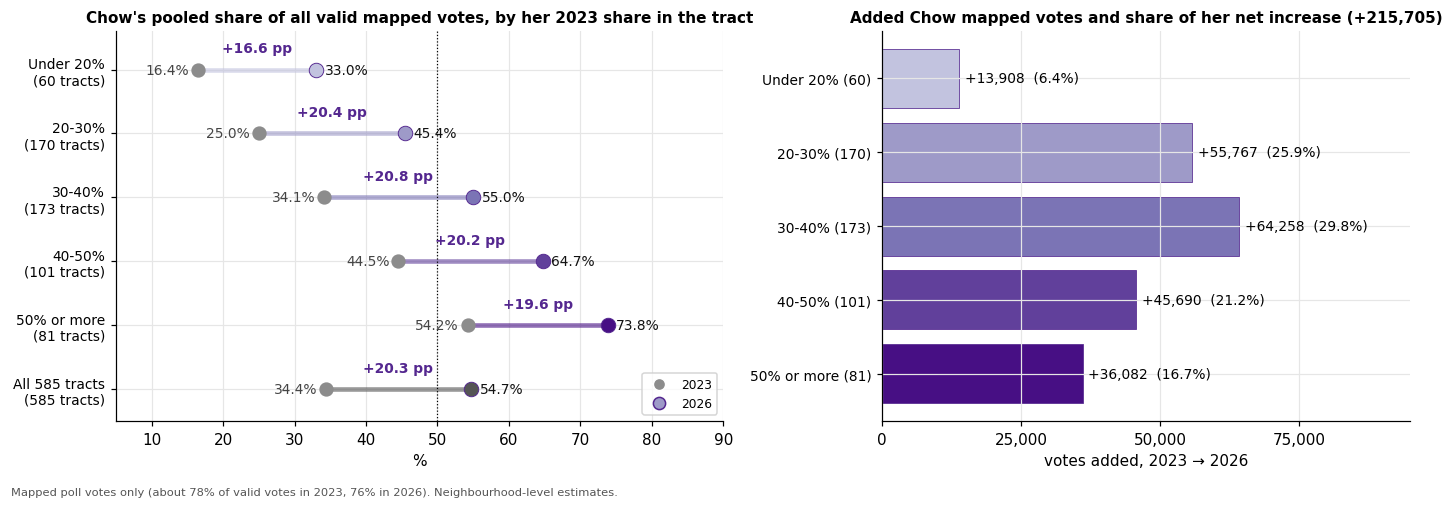

,tracts,Chow % 2023,Chow % 2026,gain (pp),added votes,% of her net increase,% of 2026 valid mapped votes,growth in valid mapped votes (%)
Under 20%,60.0,16.4,33.0,16.6,"13,908.0",6.4,9.8,17.0
20-30%,170.0,25.0,45.4,20.4,"55,767.0",25.9,28.4,29.8
30-40%,173.0,34.1,55.0,20.8,"64,258.0",29.8,28.3,38.0
40-50%,101.0,44.5,64.7,20.2,"45,690.0",21.2,18.7,38.7
50% or more,81.0,54.2,73.8,19.6,"36,082.0",16.7,14.8,31.3


Tracts by 2023 share band and head-to-head transition group:


group,Established support,Newly leading,Persistent opposition lead,Reverse transition,Exact tie,All
band,,,,,,
Under 20%,0,0,60,0,0,60
20-30%,2,61,106,0,1,170
30-40%,72,85,11,2,3,173
40-50%,101,0,0,0,0,101
50% or more,81,0,0,0,0,81
All,256,146,177,2,4,585


In [7]:
t["band"] = pd.cut(t.chow23, BAND_EDGES, labels=BAND_LABELS, right=False)
assert t.band.notna().all()
B = pd.DataFrame({b: pooled(t[t.band == b]) for b in BAND_LABELS}).T
B["gain_pp"] = B.chow26 - B.chow23; B["share_of_increase"] = B.add_chow / ALL.add_chow * 100
assert np.isclose(B.add_chow.sum(), ALL.add_chow) and np.isclose(B.share_of_increase.sum(), 100) and int(B.tracts.sum()) == 585
BCOL = dict(zip(BAND_LABELS, plt.cm.Purples(np.linspace(.35, .95, len(BAND_LABELS)))))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
rows = BAND_LABELS + ["All 585 tracts"]; y = np.arange(len(rows))[::-1]
a = ax[0]
for yy, g in zip(y, rows):
    r = ALL if g == "All 585 tracts" else B.loc[g]; colr = "#555555" if g == "All 585 tracts" else BCOL[g]
    a.hlines(yy, r.chow23, r.chow26, color=colr, lw=3, alpha=.6); a.scatter(r.chow23, yy, color=C23, s=70, zorder=3); a.scatter(r.chow26, yy, color=colr, s=90, zorder=4, edgecolor="#54278f", linewidth=.6)
    a.text(r.chow23 - 1.2, yy, f"{r.chow23:.1f}%", ha="right", va="center", fontsize=9, color="#444"); a.text(r.chow26 + 1.2, yy, f"{r.chow26:.1f}%", ha="left", va="center", fontsize=9, color="#111")
    a.text((r.chow23 + r.chow26) / 2, yy + .27, f"+{r.chow26 - r.chow23:.1f} pp", ha="center", fontsize=9, fontweight="bold", color="#54278f")
a.axvline(50, color="k", ls=":", lw=.8); a.set_yticks(y); a.set_yticklabels([f"{g}\n({int(B.loc[g, 'tracts']) if g in B.index else 585} tracts)" for g in rows], fontsize=9); a.set_xlim(5, 90); a.set_ylim(-.5, len(rows) - .4)
a.set(title="Chow's pooled share of all valid mapped votes, by her 2023 share in the tract", xlabel="%"); a.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=C23, ms=8, label="2023"), Line2D([], [], marker="o", color="w", markerfacecolor="#9e9ac8", markeredgecolor="#54278f", ms=8, label="2026")], fontsize=8, loc="lower right")
a = ax[1]; y2 = np.arange(len(BAND_LABELS))[::-1]
a.barh(y2, [B.loc[g, "add_chow"] for g in BAND_LABELS], color=[BCOL[g] for g in BAND_LABELS], edgecolor="#54278f", linewidth=.5)
for yy, g in zip(y2, BAND_LABELS):
    a.text(B.loc[g, "add_chow"] + 1000, yy, f"+{B.loc[g, 'add_chow']:,.0f}  ({B.loc[g, 'share_of_increase']:.1f}%)", va="center", fontsize=9)
a.set_yticks(y2); a.set_yticklabels([f"{g} ({int(B.loc[g, 'tracts'])})" for g in BAND_LABELS], fontsize=9); a.set_xlim(0, 95000); a.set_xticks([0, 25000, 50000, 75000]); a.set_xticklabels(["0", "25,000", "50,000", "75,000"])
a.set(title=f"Added Chow mapped votes and share of her net increase (+{ALL.add_chow:,.0f})", xlabel="votes added, 2023 → 2026")
foot(fig); plt.tight_layout(rect=(0, .03, 1, 1)); plt.show()
B["share_of_valid26"] = B.valid26 / ALL.valid26 * 100; B["valid_growth_pct"] = (B.valid26 / B.valid23 - 1) * 100
display(B[["tracts", "chow23", "chow26", "gain_pp", "add_chow", "share_of_increase", "share_of_valid26", "valid_growth_pct"]].rename(columns={"chow23": "Chow % 2023", "chow26": "Chow % 2026", "gain_pp": "gain (pp)", "add_chow": "added votes", "share_of_increase": "% of her net increase", "share_of_valid26": "% of 2026 valid mapped votes", "valid_growth_pct": "growth in valid mapped votes (%)"}).round(1))
print("Tracts by 2023 share band and head-to-head transition group:"); display(pd.crosstab(t.band, t.group.where(t.group.isin(GROUPS)), margins=True)[GROUPS + ["All"]])

**Gains by 2023 share band.** Chow's pooled share rose by about 20 points in every band except the lowest: **+16.6 (under 20%), +20.4 (20-30%), +20.8 (30-40%), +20.2 (40-50%) and +19.6 (50% or more)**, against +20.3 citywide. Where she started below 20% she reached 33.0%; where she started at 50% or more she reached 73.8%. So the gain was close to a uniform shift upward rather than being concentrated in her weakest or strongest tracts. Her net increase of 215,705 mapped votes was spread roughly in proportion to where the votes are: **the 20-30% and 30-40% bands supplied 55.7% of it (25.9% and 29.8%), tracts at 40% or more supplied 37.9%, and tracts under 20% only 6.4%** (those 60 tracts hold 9.8% of 2026 valid mapped votes, and their valid vote grew only 17%, against 30-39% in the other bands). The bands line up closely with the transition groups: every tract at 40% or more (182) is established support, every tract under 20% (60) is persistent opposition, and every newly leading tract (146) was in the 20-40% bands, so the 30-40% band is the mixed one (72 established, 85 newly leading, 11 persistent opposition). These are descriptive bands of an outcome measured in 2023, so some regression to the mean is built in (see the note above).

### The strength of the change against the main opponent

The classification only records which side led. This map shows the change in Chow's share of the **Chow + main-opponent vote** (her 2026 pair share minus her 2023 pair share), centred on zero: purple means her position against the main opponent improved, green means it worsened. It applies to every tract, including those that stayed in the same category, and ignores everyone else's votes.

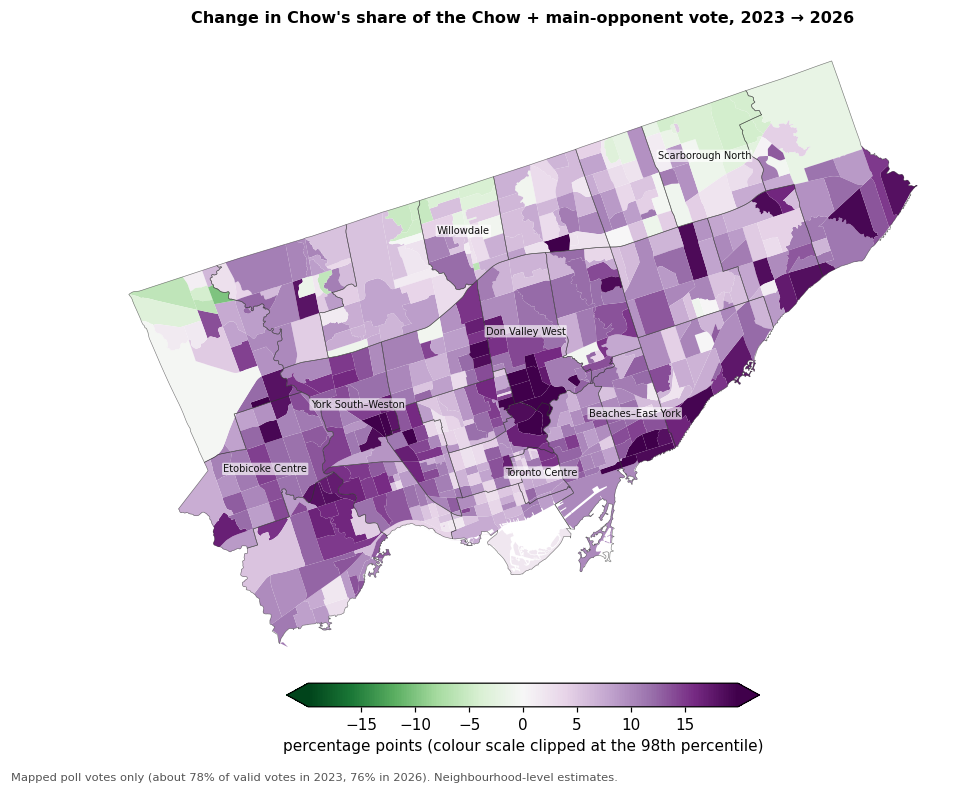

,tracts,median_change_pair,pct_tracts_pair_fell,median_change_share
group,,,,
Established support,256,6.9,10.2,20.3
Newly leading,146,11.4,0.0,22.5
Persistent opposition lead,177,9.8,8.5,17.2
Reverse transition,2,-4.6,100.0,12.8
Exact tie,4,7.4,0.0,17.9


Chow's all-candidate share rose in 585 of 585 tracts; her pair share fell in 43. Citywide median pair-share change 9.1 pp.


In [8]:
lim = np.nanpercentile(np.abs(t.d_pair), 98); norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
fig, ax = plt.subplots(figsize=(9.5, 7.2))
tp.plot(column="d_pair", cmap="PRGn_r", norm=norm, ax=ax, linewidth=0); draw_wards(ax); ax.set_axis_off()
fig.colorbar(ScalarMappable(norm=norm, cmap="PRGn_r"), ax=ax, orientation="horizontal", fraction=.035, pad=.01, shrink=.7, label="percentage points (colour scale clipped at the 98th percentile)", extend="both")
ax.set_title("Change in Chow's share of the Chow + main-opponent vote, 2023 → 2026", fontsize=10.5); foot(fig); plt.tight_layout(rect=(0, .02, 1, 1)); plt.show()
cmp_ = t.groupby("group").agg(tracts=("d_pair", "size"), median_change_pair=("d_pair", "median"), pct_tracts_pair_fell=("d_pair", lambda s: (s < 0).mean() * 100), median_change_share=("d_chow", "median")).reindex(GROUPS)
display(cmp_.round(1))
print(f"Chow's all-candidate share rose in {int((t.d_chow > 0).sum())} of 585 tracts; her pair share fell in {int((t.d_pair < 0).sum())}. Citywide median pair-share change {t.d_pair.median():.1f} pp.")

**Strength of the change against the main opponent.** Chow's all-candidate share rose in all 585 tracts, but her share of the two-candidate vote fell in 43 (7%). The improvement was largest across the central, east-end and west-central tracts and weakest, with the only declines (green), along the northern edge and in the north-west corner, near the labelled Willowdale and Scarborough North wards. The change was largest in the newly leading group (median +11.4 points, no tract with a decline), smaller in persistent-opposition tracts (+9.8; 8.5% of tracts declined) and smallest in established-support tracts (+6.9; 10.2% declined). Her position against her opponent therefore improved in most tracts that stayed in the same category too, and the biggest improvements were in places that crossed from trailing to leading.

## 2. Raw transitions and a robustness check

The category map uses only the sign of the lead, so a one-point crossover and a twenty-point crossover look the same. Two checks follow: (a) **near-ties**, setting aside tracts within **2 points of an even contest** (in the all-candidate Chow-minus-opponent margin) in either election; and (b) a **vote-weighted view** of how much of the mapped vote, not just how many tracts, each group holds.

### 2.1 Setting aside near-ties

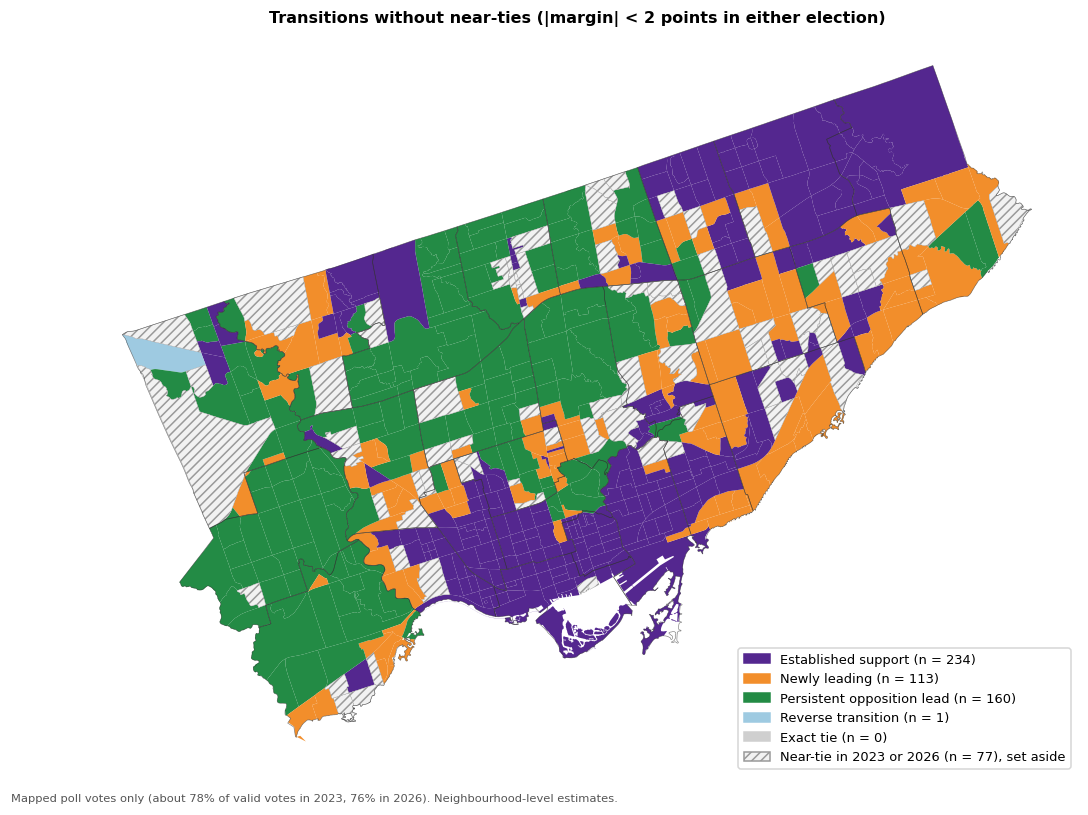

,tracts,Established support: tracts,Newly leading: tracts,Persistent opposition lead: tracts,Established support: % of added votes,Newly leading: % of added votes,Persistent opposition lead: % of added votes
all tracts,585.0,256.0,146.0,177.0,50.5,26.7,22.2
excluding near-ties,508.0,234.0,113.0,160.0,53.5,24.1,22.3
excluding small tracts (< 300 votes),557.0,240.0,143.0,169.0,50.4,26.8,22.1
excluding both,482.0,218.0,110.0,153.0,53.4,24.2,22.3


Median newly leading tract, with and without near-ties (units as in section 4; income as percentile):


,all newly leading,"newly leading, excluding near-ties"
Renter households,39.9,42.6
Single-detached dwellings,29.4,27.8
Median household income (tract percentile),49.6,47.3
Commute by car,66.0,65.8
Commute by walking or cycling,4.3,4.6
University degree,32.1,31.5


Near-ties by group: {'Established support': 22, 'Newly leading': 33, 'Persistent opposition lead': 17, 'Reverse transition': 1, 'Exact tie': 4}


In [9]:
near = (t.margin23.abs() < NEAR_TIE_PP) | (t.margin26.abs() < NEAR_TIE_PP)
tp["near"] = near.values; tp["code2"] = pd.Categorical(tp.group, categories=GROUPS).codes
fig, ax = plt.subplots(figsize=(10.5, 7.4))
tp[~tp.near].plot(column="code2", cmap=ListedColormap([GROUP_COLOURS[g] for g in GROUPS]), vmin=0, vmax=len(GROUPS) - 1, ax=ax, linewidth=0)
tp[tp.near].plot(ax=ax, color="#f2f2f2", edgecolor="#9a9a9a", linewidth=.25, hatch="////"); draw_wards(ax, labels=False); ax.set_axis_off()
conf = {g: int(((t.group == g) & ~near).sum()) for g in GROUPS}
ax.legend(handles=[Patch(color=GROUP_COLOURS[g], label=f"{g} (n = {conf[g]})") for g in GROUPS] + [Patch(facecolor="#f2f2f2", edgecolor="#9a9a9a", hatch="////", label=f"Near-tie in 2023 or 2026 (n = {int(near.sum())}), set aside")],
          loc="lower right", fontsize=8.5, frameon=True)
ax.set_title(f"Transitions without near-ties (|margin| < {NEAR_TIE_PP} points in either election)", fontsize=10.5); foot(fig); plt.tight_layout(rect=(0, .02, 1, 1)); plt.show()

def summary(mask):
    d = t[mask]; add = d.chow_v26.sum() - d.chow_v23.sum()
    r = {"tracts": len(d)}
    for g in MAIN: r[f"{g}: tracts"] = int((d.group == g).sum())
    for g in MAIN: r[f"{g}: % of added votes"] = (d[d.group == g].chow_v26.sum() - d[d.group == g].chow_v23.sum()) / add * 100
    return r
S = pd.DataFrame({"all tracts": summary(t.index == t.index), "excluding near-ties": summary(~near), f"excluding small tracts (< {MIN_VALID_VOTES} votes)": summary(t.big), "excluding both": summary(~near & t.big)}).T
display(S.round(1))
nl = t.group == "Newly leading"
demo = pd.DataFrame({"all newly leading": {CENSUS[c][0] if c != "income_pct" else "Median household income (tract percentile)": t.loc[nl, c].median() * (CENSUS[c][2] if c in CENSUS else 1) for c in ("hhtnrent_pct", "dwtpsdet_pct", "income_pct", "jwmdauto_pct", "walkbike", "edcauniv_pct")},
                     "newly leading, excluding near-ties": {CENSUS[c][0] if c != "income_pct" else "Median household income (tract percentile)": t.loc[nl & ~near, c].median() * (CENSUS[c][2] if c in CENSUS else 1) for c in ("hhtnrent_pct", "dwtpsdet_pct", "income_pct", "jwmdauto_pct", "walkbike", "edcauniv_pct")}})
print("Median newly leading tract, with and without near-ties (units as in section 4; income as percentile):"); display(demo.round(1))
print(f"Near-ties by group: {t[near].group.value_counts().reindex(GROUPS).fillna(0).astype(int).to_dict()}")

**Does the raw classification hold up?** Setting aside the 77 tracts within 2 points of an even contest in either election leaves 508 tracts: **234 established, 113 newly leading, 160 persistent opposition, 1 reverse**. Newly leading is the group most affected (33 of its 146 tracts, 23%, are near-ties, versus 22 of 256 established and 17 of 177 persistent), so its boundary is the softest. The picture is unchanged: the established share of added votes rises to 53.5%, newly leading falls to 24.1% and persistent opposition stays at 22.3%. The remaining newly leading tracts are in the same parts of the map, and their median profile is similar (renters 43% vs. 40%, single-detached 28% vs. 29%, car commuting 66% vs. 66%, income percentile 47 vs. 50). Dropping tracts with under 300 valid votes changes almost nothing (143 newly leading, 26.8% of added votes).

### 2.2 Tracts vs. votes

Each group's share of the **585 tracts** next to its share of **all valid mapped votes in 2026** (weights are 2026 valid mapped votes in each tract). This asks whether a group accounts for more or less of the vote than of the map; it is separate from the near-tie check (strength of lead) and from each group's share of Chow's added votes (Section 1).

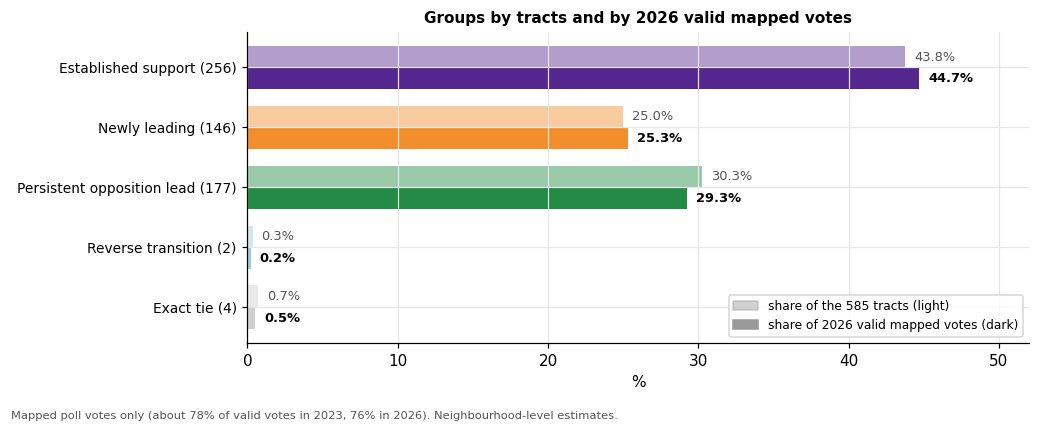

In [10]:
tr_share = t.group.value_counts(normalize=True).reindex(GROUPS) * 100
vv_share = t.groupby("group").valid26.sum().reindex(GROUPS) / t.valid26.sum() * 100
fig, ax = plt.subplots(figsize=(9.5, 3.9)); y = np.arange(len(GROUPS))[::-1]; h = .36
ax.barh(y + h / 2, tr_share, height=h, color=[GROUP_COLOURS[g] for g in GROUPS], alpha=.45, label="share of the 585 tracts")
ax.barh(y - h / 2, vv_share, height=h, color=[GROUP_COLOURS[g] for g in GROUPS], label="share of all 2026 valid mapped votes")
for yy, g in zip(y, GROUPS):
    ax.text(tr_share[g] + .6, yy + h / 2, f"{tr_share[g]:.1f}%", va="center", fontsize=8.5, color="#555"); ax.text(vv_share[g] + .6, yy - h / 2, f"{vv_share[g]:.1f}%", va="center", fontsize=8.5, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels([f"{g} ({int((t.group == g).sum())})" for g in GROUPS], fontsize=9); ax.set_xlim(0, 52); ax.set(xlabel="%", title="Groups by tracts and by 2026 valid mapped votes")
ax.legend(handles=[Patch(color="#999", alpha=.45, label="share of the 585 tracts (light)"), Patch(color="#999", label="share of 2026 valid mapped votes (dark)")], fontsize=8, loc="lower right"); foot(fig); plt.tight_layout(rect=(0, .04, 1, 1)); plt.show()

**Tracts vs. votes.** The groups hold about the same share of the vote as of the map: established support is 43.8% of tracts and 44.7% of 2026 valid mapped votes, newly leading 25.0% and 25.3%, persistent opposition 30.3% and 29.3%. So the newly leading tracts are not unusually small or large; a quarter of the places is a quarter of the vote. (This is a vote-volume check; it is distinct from the near-tie check above and from the groups' shares of Chow's added votes.)

## 3. How the demographic relationships changed

Pearson correlations across tracts between each census variable and **each candidate's share of all valid mapped votes**: Chow in 2023 and 2026 (and the change in her share; her 2014 share is added in the leftmost column and explained below), and the main opponent (Bailão in 2023, Bradford in 2026, and the 2026 minus 2023 difference, which compares **two different candidates' geographic patterns**). For each variable the same tracts are used in all six 2023-2026 columns (tracts with missing census values are dropped, and *n* is in the label, with the 2014 column's *n* alongside). Income is the original `ihat_med__nc` ("Median Household Income", dollars; the metadata give no reference year, which does not matter for a one-year correlation across tracts). Car, transit and walk-or-cycle commuting share one denominator (commuters), so they are comparable; walking and cycling are combined.

In [11]:
# Chow's 2014 tract vote and the 2011 census on the same 585 2021 tracts (the project's harmonised tract files)
el14 = pd.read_parquet(ELECTIONS_PARQUET).query("year == 2014 and candidate == 'chow'").set_index("ct")[["share", "votes"]]
cen11 = pd.read_parquet(CENSUS_PARQUET).query("year == 2011").set_index("ct")
assert set(el14.index) == set(cen11.index) == set(t.ctuid2021) and len(el14) == 585
t14 = pd.DataFrame({"chow14": el14["share"] * 100, "chow_v14": el14["votes"]}).join(cen11)
t14["walkbike"] = t14.jwmdwalk_pct + t14.jwmdbike_pct
t14 = t14.reindex(t.ctuid2021)                                             # same tract order as `t`
print(f"2014 Chow share across tracts: median {t14.chow14.median():.1f}%, range {t14.chow14.min():.1f}-{t14.chow14.max():.1f}%; "
      f"citywide pooled {t14.chow_v14.sum() / pd.read_parquet(SOCGEO_DIR / 'turnout.parquet').query('year == 2014').votes_cast.sum() * 100:.1f}% of mapped votes cast")
print("Tracts missing 2011 census values by variable:", {v: int(t14[v].isna().sum()) for v in CORR_VARS if t14[v].isna().any()})

2014 Chow share across tracts: median 19.0%, range 6.8-79.3%; citywide pooled 23.4% of mapped votes cast
Tracts missing 2011 census values by variable: {'hhtnrent_pct': 6, 'ihat_med__nc': 7, 'jwmdauto_pct': 6, 'jwmdtran_pct': 6, 'walkbike': 6, 'vminvisi_pct': 6, 'imstimmi_pct': 6}


### 2014 baseline (2011 census)

A third election is added for Chow only: **2014**, when she finished third (Tory, Ford, Chow). It uses the project's tract-level 2014 results (on the same 585 2021 tracts) and the **2011 census/NHS** for the same tracts, so the 2014 column pairs her 2014 share with 2011 neighbourhood characteristics, whereas 2023 and 2026 use the 2021 census. Cautions: (1) the 2011 income and other long-form items come from the **voluntary National Household Survey**, with higher non-response than the 2021 census (6-7 tracts have missing 2011 values, against 2 in 2021, so *n* differs by column and the 2023/2026 columns are unchanged); (2) the 2014 tract file covers about **84% of votes** (820,616 vs. roughly 980,000 in the official results) and its share is a **share of votes cast**, not of valid candidate votes (r = 0.9996 with her share of the three leading candidates' votes); (3) the 2014 field and her position were different (third place with 23% rather than first), so comparisons across years are about whether *the pattern across neighbourhoods* is similar, not about vote levels, which Pearson correlations ignore.

Metadata labels: income = Median Household Income (dollars); commuting universe = Commute - Total | renters universe = Dwellings - Tenure - Total | detached universe = Dwellings - Type - Total


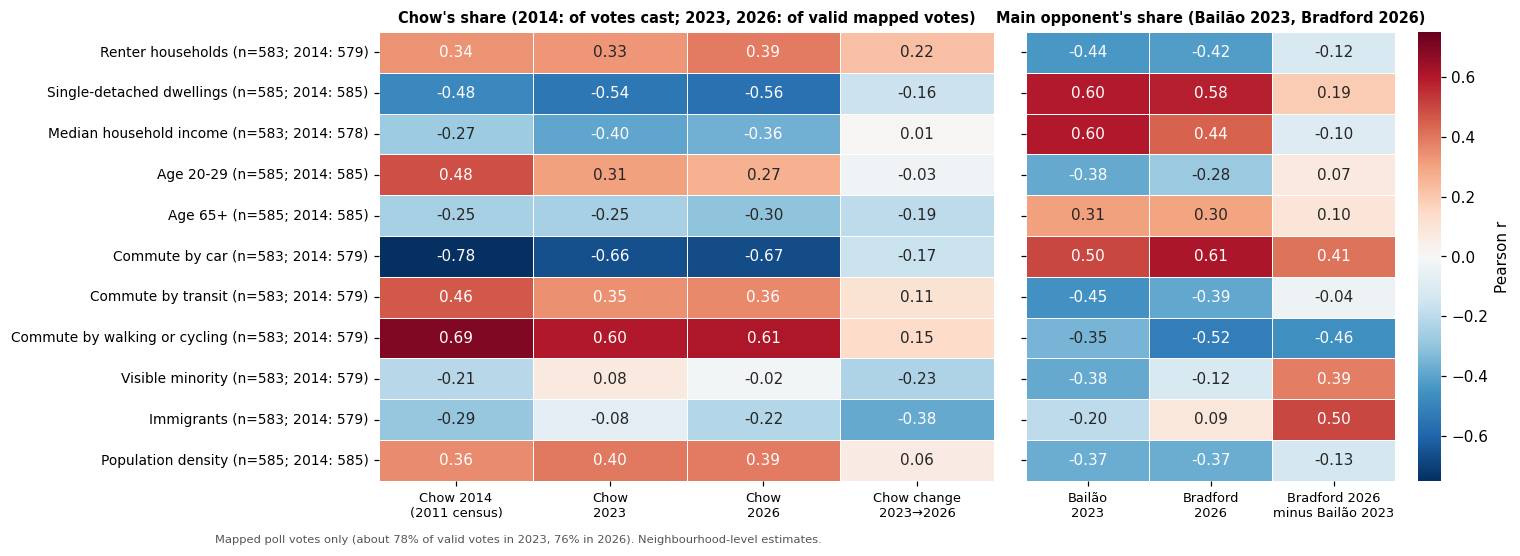

Reading note: the 2014 column pairs her 2014 share of votes cast with 2011 census values; the 2023 and 2026 columns use the 2021 census.


In [12]:
meta = json.load(open(CENSUS_META)); by_id = {v["id"]: v for v in meta["variables"]}; by_nom = {v["nom"]: v for v in meta["variables"] if v.get("nom")}
assert by_id["jwmdwalk_pct"]["den"] == by_id["jwmdbike_pct"]["den"] == by_id["jwmdauto_pct"]["den"] == by_id["jwmdtran_pct"]["den"]
print("Metadata labels: income =", by_nom["ihat_med__nc"]["label"], f"({by_nom['ihat_med__nc']['unit']}); commuting universe =", by_id["jwmdauto_pct"]["den_label"], "| renters universe =", by_id["hhtnrent_pct"]["den_label"], "| detached universe =", by_id["dwtpsdet_pct"]["den_label"])
SIX = [("chow23", "Chow\n2023"), ("chow26", "Chow\n2026"), ("d_chow", "Chow change\n2023→2026"), ("opp23", "Bailão\n2023"), ("opp26", "Bradford\n2026"), ("d_opp", "Bradford 2026\nminus Bailão 2023")]
R = {}; N = {}; R14 = {}; N14 = {}
for v in CORR_VARS:
    d = t[[v] + [c for c, _ in SIX]].dropna(); N[v] = len(d); R[v] = {c: d[v].corr(d[c]) for c, _ in SIX}          # 2021 census, as before
    d14 = pd.DataFrame({"x": t14[v], "y": t14.chow14}).dropna(); N14[v] = len(d14); R14[v] = d14.x.corr(d14.y)       # 2011 census with 2014 share
R = pd.DataFrame(R).T; R.insert(0, "chow14", pd.Series(R14))
R.index = [f"{CENSUS[v][0]} (n={N[v]}; 2014: {N14[v]})" for v in CORR_VARS]
LEFT = [("chow14", "Chow 2014\n(2011 census)")] + SIX[:3]
fig, ax = plt.subplots(1, 2, figsize=(13, 5.3), sharey=True, gridspec_kw={"wspace": .06, "width_ratios": [4, 3]})
for a, cols, ttl in zip(ax, (LEFT, SIX[3:]), ("Chow's share (2014: of votes cast; 2023, 2026: of valid mapped votes)", "Main opponent's share (Bailão 2023, Bradford 2026)")):
    sns.heatmap(R[[c for c, _ in cols]].set_axis([l for _, l in cols], axis=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.75, vmax=.75, linewidths=.5, ax=a, cbar=a is ax[1], cbar_kws={"label": "Pearson r"} if a is ax[1] else None)
    a.set_title(ttl, fontsize=9.5); a.tick_params(axis="x", labelsize=8.5); a.grid(False)
ax[0].tick_params(axis="y", labelsize=9); foot(fig, .0); plt.tight_layout(rect=(0, .02, 1, 1)); plt.show()
print("Reading note: the 2014 column pairs her 2014 share of votes cast with 2011 census values; the 2023 and 2026 columns use the 2021 census.")

**Overview.** Chow's neighbourhood pattern is essentially the same in both elections: her share is higher in tracts with more renters (0.33 → 0.39), more walkers and cyclists (0.60 → 0.61) and more transit commuters (0.35 → 0.36), and lower where car commuting (−0.66 → −0.67), detached housing (−0.54 → −0.56) or income (−0.40 → −0.36) is higher. The one clear change is for immigrant share (−0.08 → −0.22). In the "change" column, her gains were smaller where immigrant (−0.38) and visible-minority (−0.23) shares were higher, and slightly larger where renters were more numerous (+0.22). The **main opponent's pattern shifted more**: Bradford's share is *less* tied to income than Bailão's was (+0.60 → +0.44), *more* tied to car commuting (+0.50 → +0.61) and to low walking/cycling (−0.35 → −0.52), and no longer negatively related to visible-minority share (−0.38 → −0.12) or immigrant share (−0.20 → +0.09). The difference column compares two different candidates' maps: Bradford's share exceeded Bailão's more in tracts with more immigrants (+0.50), visible minorities (+0.39) and car commuters (+0.41).

**2014 baseline (2011 census).** In 2014 Chow's neighbourhood pattern had the *same signs* as in 2023 and 2026 for every variable except visible-minority share, and for the commuting, age and density variables it was as strong or stronger: car commuting −0.78 (2023: −0.66, 2026: −0.67), walking or cycling +0.69 (+0.60, +0.61), transit +0.46 (+0.35, +0.36), age 20-29 +0.48 (+0.31, +0.27). The renter (+0.34), density (+0.36) and age 65+ (−0.25) relationships are close to the later ones. The relationships that were weaker in 2014 are income (−0.27, against −0.40 and −0.36) and detached housing (−0.48, against −0.54 and −0.56). Two relationships moved and partly came back: immigrant share (−0.29 → −0.08 → −0.22) and visible-minority share (−0.21 → +0.08 → −0.02). So the 2023 and 2026 coalition looks like a softer version of the 2014 one on commuting and age, and a more income-and-housing-stratified one. Read this as a comparison of *patterns across neighbourhoods*, with the caveats above: the census vintage changes with the election (2011 survey vs. 2021 census, the latter's commuting data collected during the pandemic: median car commuting share 57% in 2011, 63% in 2021, transit 36% to 25%), and the 2014 field and her vote level (23%, third place) were different.

### Persistent or changed? Paired dots

A handful of variables, with each candidate's earlier coefficient(s) joined to the 2026 one (colour) on a common scale. Left: Chow's share, with **2014 (2011 census, light purple)**, 2023 (grey) and 2026 (deep purple) on one line. Right: the main opponent's share (Bailão, then Bradford, so the line connects two different candidates' patterns).

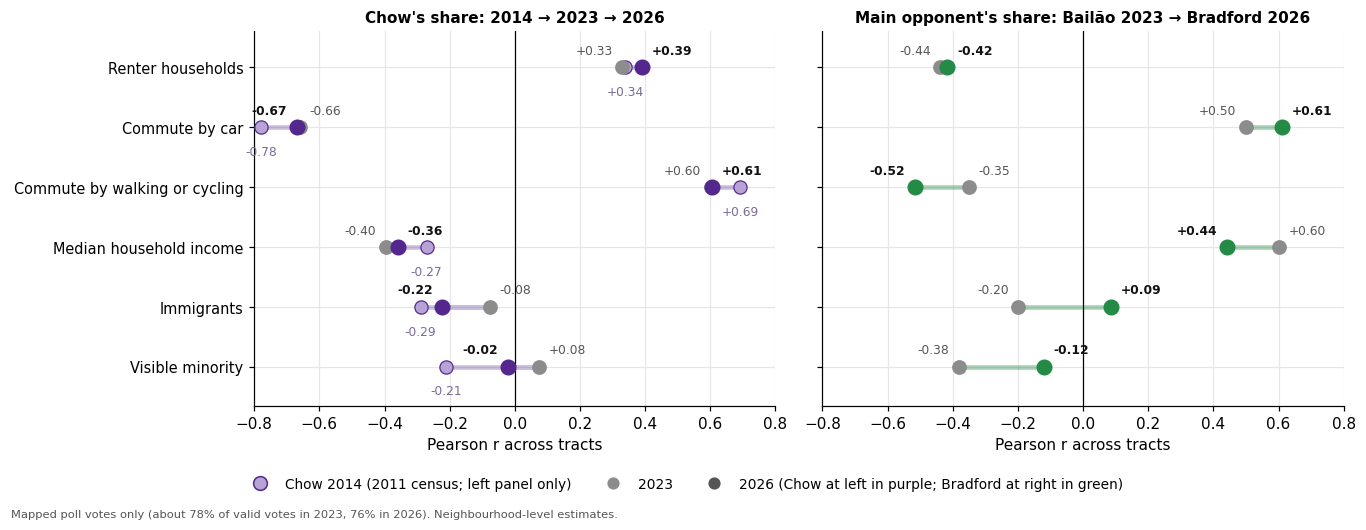

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
order = PAIRED_VARS[::-1]
for a, (c23, c26, colr, ttl) in zip(ax, (("chow23", "chow26", CHOW, "Chow's share: 2014 → 2023 → 2026"), ("opp23", "opp26", OPP, "Main opponent's share: Bailão 2023 → Bradford 2026"))):
    for yy, v in enumerate(order):
        d = t[[v, c23, c26]].dropna(); r23, r26 = d[v].corr(d[c23]), d[v].corr(d[c26])
        up = r23 < r26
        if a is ax[0]:
            d14 = pd.DataFrame({"x": t14[v], "y": t14.chow14}).dropna(); r14 = d14.x.corr(d14.y)
            a.plot([r14, r23, r26], [yy, yy, yy], color=colr, lw=3, alpha=.3, zorder=2); a.scatter(r14, yy, color=CHOW_2014_LIGHT, s=75, zorder=3, edgecolor=CHOW, linewidth=.8)
            a.text(r14, yy - .3, f"{r14:+.2f}", ha="center", va="top", fontsize=8, color="#7a6a9a")
        else:
            a.hlines(yy, r23, r26, color=colr, lw=3, alpha=.4)
        a.scatter(r23, yy, color=C23, s=75, zorder=3); a.scatter(r26, yy, color=colr, s=90, zorder=4)
        a.text(r23 + (-.03 if up else .03), yy + .22, f"{r23:+.2f}", ha="right" if up else "left", fontsize=8, color="#555"); a.text(r26 + (.03 if up else -.03), yy + .22, f"{r26:+.2f}", ha="left" if up else "right", fontsize=8, color="#111", fontweight="bold")
    a.axvline(0, color="k", lw=.8); a.set(xlim=(-.8, .8), ylim=(-.65, len(order) - .4), title=ttl, xlabel="Pearson r across tracts"); a.set_yticks(range(len(order))); a.set_yticklabels([CENSUS[v][0] for v in order], fontsize=9.5)
fig.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=CHOW_2014_LIGHT, markeredgecolor=CHOW, ms=9, label="Chow 2014 (2011 census; left panel only)"), Line2D([], [], marker="o", color="w", markerfacecolor=C23, ms=9, label="2023"), Line2D([], [], marker="o", color="w", markerfacecolor="#555", ms=9, label="2026 (Chow at left in purple; Bradford at right in green)")], loc="lower center", bbox_to_anchor=(.5, .035), ncol=3, frameon=False, fontsize=9)
foot(fig); plt.tight_layout(rect=(0, .1, 1, 1)); plt.show()

**What persisted and what changed.** On the left, Chow's dots barely move for renters, car commuting, walking or cycling and income: those relationships persisted. Only the immigrant (−0.08 → −0.22) and visible-minority (+0.08 → −0.02) dots move noticeably. On the right, the opponent's dots move much more: the link to car commuting strengthens and the negative link to walking and cycling deepens, the link to income weakens, and the immigrant and visible-minority relationships turn from negative towards zero or positive. Within the larger share she gained, Chow's coalition by neighbourhood type changed little between 2023 and 2026; the notable shift is in what kinds of neighbourhoods supported her main opponent.

**Adding 2014 (2011 census, light purple).** The left panel's line now starts in 2014. The 2014-to-2023 steps are larger than the 2023-to-2026 steps for most variables, but they are the least comparable, since both the census (2011 NHS vs. 2021) and the election (a three-way race she lost vs. a race she led) differ. Commuting and age patterns were stronger in 2014 (car commuting −0.78 → −0.66 → −0.67; walking or cycling +0.69 → +0.60 → +0.61). Income was less related to her vote in 2014 (−0.27 → −0.40 → −0.36), and renters were about the same (+0.34 → +0.33 → +0.39). Immigrant (−0.29 → −0.08 → −0.22) and visible-minority (−0.21 → +0.08 → −0.02) shares moved toward zero in 2023 and partly back in 2026.

### Two suburban case studies: outside Old Toronto, and Scarborough

The same correlations, repeated within two parts of the city. **Suburbs** are every tract outside the former City of Toronto ("Old Toronto"): East York, Etobicoke, North York, Scarborough and York, the definition used elsewhere on the site. **Scarborough** is one of those five (it is included in the suburbs). Tracts are assigned to the former municipality that covers most of their area (the lowest overlap is 95%, so the assignment is essentially unambiguous). Each figure has the same layout as the citywide heatmap above: Chow's 2014 (2011 census), 2023 and 2026 shares and the change in her share, and the main opponent's shares. Correlations *within* a part of the city can differ from the citywide ones because the citywide pattern partly reflects differences *between* Old Toronto and the suburbs. With 126 Scarborough tracts, correlations smaller than about 0.2 in absolute value should not be read as different from zero, and neighbouring tracts are alike, so the effective sample is smaller still.

Tracts by former municipality: {'Old Toronto': 179, 'North York': 142, 'Scarborough': 126, 'Etobicoke': 79, 'York': 32, 'East York': 27} | suburbs: 406 | minimum share of a tract in its assigned municipality: 0.952


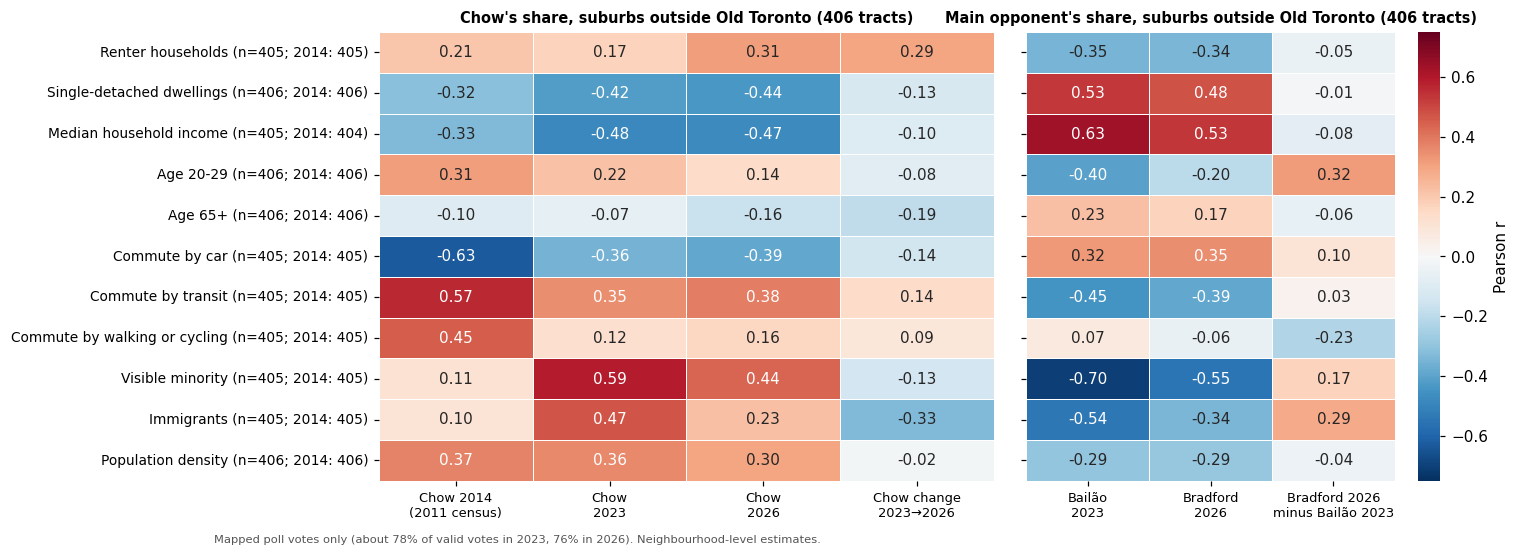

In [14]:
fm = gpd.read_file(FORMER_MUNI).to_crs(PROJECTED_EPSG)
ov = gpd.overlay(tp[["ctuid2021", "geometry"]], fm[["name", "geometry"]], how="intersection"); ov["area"] = ov.area
ov["share"] = ov.area / ov.ctuid2021.map(tp.set_index("ctuid2021").geometry.area)
top = ov.sort_values("area").groupby("ctuid2021").tail(1).set_index("ctuid2021")
assert len(top) == 585 and top.share.min() > .9
t["muni"] = t.ctuid2021.map(top["name"]); t["suburb"] = t.muni != "Old Toronto"
print("Tracts by former municipality:", t.muni.value_counts().to_dict(), f"| suburbs: {int(t.suburb.sum())} | minimum share of a tract in its assigned municipality: {top.share.min():.3f}")

def corr_figure(mask, name):
    # same layout as the citywide heatmap, restricted to the tracts in `mask` (a boolean Series aligned to `t`)
    sub, sub14 = t[mask], t14.set_axis(t.index)[mask]
    R_, N_ = {}, {}
    for v in CORR_VARS:
        d = sub[[v] + [c for c, _ in SIX]].dropna(); R_[v] = {c: d[v].corr(d[c]) for c, _ in SIX}
        d14 = pd.DataFrame({"x": sub14[v], "y": sub14.chow14}).dropna(); R_[v]["chow14"] = d14.x.corr(d14.y); N_[v] = (len(d), len(d14))
    R_ = pd.DataFrame(R_).T; R_.index = [f"{CENSUS[v][0]} (n={N_[v][0]}; 2014: {N_[v][1]})" for v in CORR_VARS]
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.3), sharey=True, gridspec_kw={"wspace": .06, "width_ratios": [4, 3]})
    for a, cols, ttl in zip(ax, (LEFT, SIX[3:]), (f"Chow's share, {name}", f"Main opponent's share, {name}")):
        sns.heatmap(R_[[c for c, _ in cols]].set_axis([l for _, l in cols], axis=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.75, vmax=.75, linewidths=.5, ax=a, cbar=a is ax[1], cbar_kws={"label": "Pearson r"} if a is ax[1] else None)
        a.set_title(ttl, fontsize=9.5); a.tick_params(axis="x", labelsize=8.5); a.grid(False)
    ax[0].tick_params(axis="y", labelsize=9); foot(fig, .0); plt.tight_layout(rect=(0, .02, 1, 1)); plt.show()
    return R_

R_sub = corr_figure(t.suburb, f"suburbs outside Old Toronto ({int(t.suburb.sum())} tracts)")

**Suburbs outside Old Toronto (406 tracts).** Two citywide patterns look different here. First, **immigrant and visible-minority share are positively related to Chow's vote in the suburbs** (2023: +0.47 and +0.59; 2026: +0.23 and +0.44), where the citywide correlations are about zero or negative (−0.08 and +0.08 in 2023; −0.22 and −0.02 in 2026). The opponent mirrors it (Bailão −0.54 and −0.70; Bradford −0.34 and −0.55). Within Old Toronto the signs are also positive (+0.25 and +0.33 in 2023, from the comparison table below), so the near-zero citywide figures partly reflect Old Toronto, with its lower immigrant and visible-minority shares, voting more heavily for Chow than the suburbs. Second, the **commuting links are weaker** than citywide: walking or cycling +0.12 (2023) and +0.16 (2026) against +0.60 and +0.61 citywide; car commuting −0.36 and −0.39 against −0.66 and −0.67. Income is, if anything, more strongly negative for Chow (−0.48 and −0.47) and more positive for her opponent (+0.63 and +0.53). Between 2023 and 2026 the immigrant and visible-minority links weakened (+0.47 → +0.23 and +0.59 → +0.44) and the renter link strengthened (+0.17 → +0.31); in the "change" column, her gains were larger where renters were more numerous (+0.29) and smaller where immigrants were (−0.33). The 2014 column shows a different suburban pattern: strong commuting and age relationships (car −0.63, transit +0.57, walking or cycling +0.45, age 20-29 +0.31) and almost no immigrant or visible-minority link (+0.10, +0.11). The immigrant and visible-minority links appear in 2023 and the commuting links fade.

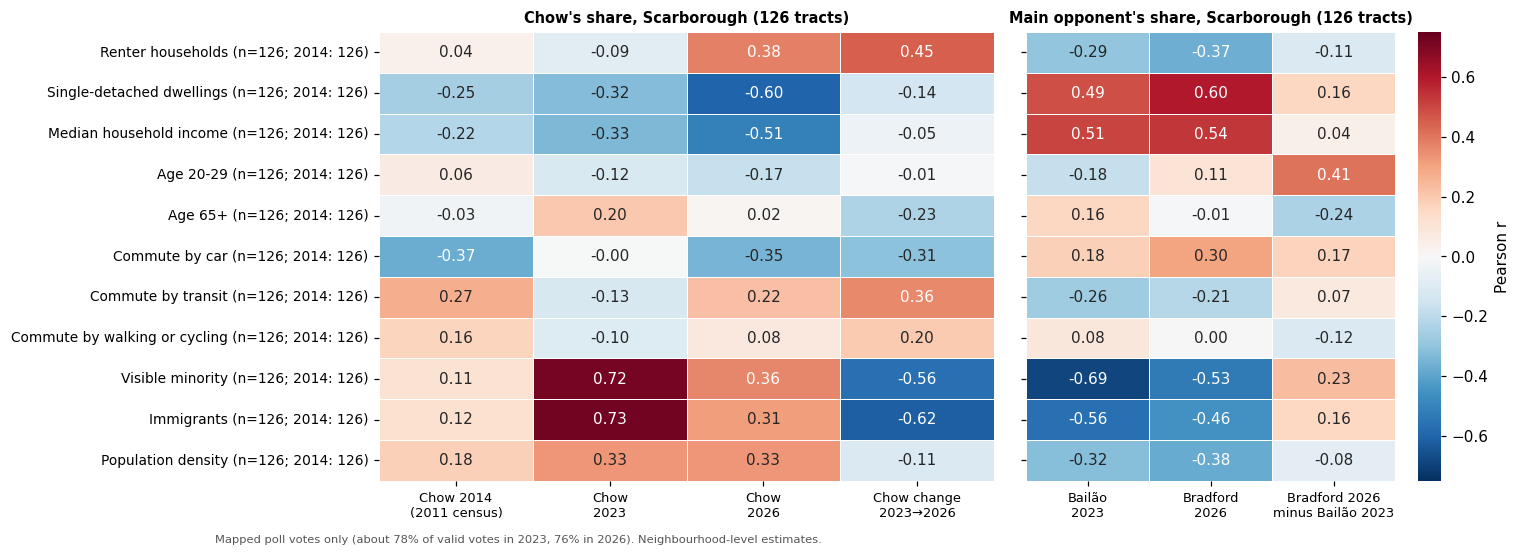

In [15]:
R_sca = corr_figure(t.muni == "Scarborough", f"Scarborough ({int((t.muni == 'Scarborough').sum())} tracts)")

**Scarborough (126 tracts).** The sharpest result in the notebook is here. In 2023 Chow's share was **strongly related to immigrant share (+0.73) and visible-minority share (+0.72)**, and Bailão's strongly and negatively related (−0.56 and −0.69), while her links to renters (−0.09), car commuting (−0.00) and transit (−0.13) were about zero. By 2026 those links had weakened (+0.31 and +0.36 for Chow; −0.46 and −0.53 for Bradford), and the pattern started to look like the rest of the city's: renters +0.38 (from −0.09), detached housing −0.60 (from −0.32), income −0.51 (from −0.33), car commuting −0.35 (from −0.00) and transit +0.22 (from −0.13). The "change" column says the same thing: her gains were larger where the immigrant (−0.62) and visible-minority (−0.56) shares were lower and where renters (+0.45), transit commuters (+0.36) and car-light tracts (−0.31) were more common. In 2014 her Scarborough relationships were all modest (no coefficient above 0.37 in absolute value). One reading is that in 2023 Chow's Scarborough support was concentrated in immigrant neighbourhoods, and in 2026 she gained most elsewhere in the borough, in neighbourhoods more like those that supported her in Old Toronto. This is a statement about how the geography of her vote changed across tracts, not about which voters switched; with 126 spatially clustered tracts, coefficients below about 0.2 are not distinguishable from zero.

In [16]:
# Side-by-side values for the commentary: each candidate-election correlation citywide, in the suburbs, in Scarborough and in Old Toronto
def cr(mask, v, c):
    d = pd.DataFrame({"x": t.loc[mask, v], "y": t.loc[mask, c]}).dropna(); return d.x.corr(d.y)
masks = {"citywide": t.index == t.index, "suburbs": t.suburb, "Scarborough": t.muni == "Scarborough", "Old Toronto": ~t.suburb}
cmp_corr = pd.DataFrame([{"candidate": lab, "variable": CENSUS[v][0], **{k: cr(m, v, c) for k, m in masks.items()}}
                         for c, lab in (("chow23", "Chow 2023"), ("chow26", "Chow 2026"), ("opp23", "Bailão 2023"), ("opp26", "Bradford 2026")) for v in CORR_VARS])
with pd.option_context("display.float_format", lambda v: f"{v:.2f}", "display.max_rows", 60):
    display(cmp_corr.set_index(["candidate", "variable"]))

citywide  suburbs  Scarborough  Old Toronto
candidate     variable                                                                  
Chow 2023     Renter households                  0.33     0.17        -0.09         0.37
              Single-detached dwellings         -0.54    -0.42        -0.32        -0.53
              Median household income           -0.40    -0.48        -0.33        -0.64
              Age 20-29                          0.31     0.22        -0.12         0.24
              Age 65+                           -0.25    -0.07         0.20        -0.31
              Commute by car                    -0.66    -0.36        -0.00        -0.56
              Commute by transit                 0.35     0.35        -0.13         0.29
              Commute by walking or cycling      0.60     0.12        -0.10         0.42
              Visible minority                   0.08     0.59         0.72         0.33
              Immigrants                        -0.08     0.47         0.73         0.25
              Population density                 0.40     0.36         0.33         0.18
Chow 2026     Renter households                  0.39     0.31         0.38         0.32
              Single-detached dwellings         -0.56    -0.44        -0.60        -0.54
              Median household income           -0.36    -0.47        -0.51        -0.61
              Age 20-29                          0.27     0.14        -0.17         0.22
              Age 65+                           -0.30    -0.16         0.02        -0.34
              Commute by car                    -0.67    -0.39        -0.35        -0.50
              Commute by transit                 0.36     0.38         0.22         0.26
              Commute by walking or cycling      0.61     0.16         0.08         0.38
              Visible minority                  -0.02     0.44         0.36         0.29
              Immigrants                        -0.22     0.23         0.31         0.17
              Population density                 0.39     0.30         0.33         0.19
Bailão 2023   Renter households                 -0.44    -0.35        -0.29        -0.51
              Single-detached dwellings          0.60     0.53         0.49         0.63
              Median household income            0.60     0.63         0.51         0.72
              Age 20-29                         -0.38    -0.40        -0.18        -0.32
              Age 65+                            0.31     0.23         0.16         0.34
              Commute by car                     0.50     0.32         0.18         0.61
              Commute by transit                -0.45    -0.45        -0.26        -0.40
              Commute by walking or cycling     -0.35     0.07         0.08        -0.41
              Visible minority                  -0.38    -0.70        -0.69        -0.43
              Immigrants                        -0.20    -0.54        -0.56        -0.33
              Population density                -0.37    -0.29        -0.32        -0.34
Bradford 2026 Renter households                 -0.42    -0.34        -0.37        -0.37
              Single-detached dwellings          0.58     0.48         0.60         0.56
              Median household income            0.44     0.53         0.54         0.65
              Age 20-29                         -0.28    -0.20         0.11        -0.21
              Age 65+                            0.30     0.17        -0.01         0.34
              Commute by car                     0.61     0.35         0.30         0.52
              Commute by transit                -0.39    -0.39        -0.21        -0.32
              Commute by walking or cycling     -0.52    -0.06         0.00        -0.37
              Visible minority                  -0.12    -0.55        -0.53        -0.33
              Immigrants                         0.09    -0.34        -0.46        -0.22
              Population density        

**Reading the comparison table.** The citywide correlations are an average of two quite different pictures. Old Toronto behaves as the citywide figures suggest on commuting (walking or cycling +0.42 and +0.38 for Chow; car −0.56 and −0.50) and income (−0.64 and −0.61), while the suburbs and Scarborough have much weaker commuting links, and positive immigrant and visible-minority links that disappear when the whole city is pooled. Income is the variable whose sign is stable everywhere (negative for Chow, positive for her opponent, and strongest in Old Toronto). The opponent's immigrant link weakened by 0.20 points in the suburbs (−0.54 → −0.34), 0.10 in Scarborough (−0.56 → −0.46) and 0.11 in Old Toronto (−0.33 → −0.22); because Bailão and Bradford are different candidates, these are changes in the opponent's geographic pattern, not in the same voters' behaviour.

## 4. Concentrated demographics: Chow's vote where a group is common vs. rare

The correlations in Section 3 use every tract and a straight-line summary. This section asks a more concrete question: **how different was Chow's vote in tracts where a characteristic is highly concentrated compared with tracts where it is scarce?** For each variable, a **high group** (at least a stated share of the tract, for example 70% or more renter households) is compared with a **low group** (at most a stated share, for example 30% or less), using Chow's **pooled share of all valid mapped votes** in each group (summed votes divided by summed valid votes, so large tracts count for more) in 2023 and 2026, and the gap **high minus low** in percentage points. A positive gap means she did better where the characteristic is concentrated. Cutoffs are chosen per variable so each group has at least 50 tracts (listed in the figures). Income uses the top and bottom 20% of tracts (percentiles 80+ and 20 or lower) because the metadata do not document the dollar basis. The 95% intervals come from a **bootstrap that resamples the 25 wards** (tracts in a ward share a political context, so resampling tracts one at a time would make the intervals too narrow). These are contrasts between **neighbourhoods**, using the 2021 census for both elections, and are not statements about voters. The middle tracts, between the cutoffs, are left out of each contrast.

In [17]:
LEVEL = {v: (t[v] if v == "income_pct" else t[v] * 100).values for v in CONTRAST}
VLAB = {v: ("Median household income (percentile)" if v == "income_pct" else CENSUS[v][0]) for v in CONTRAST}
UNIT = {v: ("" if v == "income_pct" else "%") for v in CONTRAST}
W = sorted(t.ward_dominant.unique()); wi = t.ward_dominant.map({w: i for i, w in enumerate(W)}).values
draws = np.random.default_rng(SEED).integers(0, len(W), size=(BOOT_REPS, len(W)))    # wards resampled with replacement

def by_ward(m):
    return {k: np.bincount(wi[m], weights=t.loc[m, c].values, minlength=len(W)) for k, c in (("c23", "chow_v23"), ("v23", "valid23"), ("c26", "chow_v26"), ("v26", "valid26"))}

def pooled_boot(S, y):
    return S["c" + y].sum() / S["v" + y].sum() * 100, S["c" + y][draws].sum(1) / S["v" + y][draws].sum(1) * 100

def contrast(v, region, cuts=None):
    lo, hi = cuts or CONTRAST[v]; x = LEVEL[v]
    lm, hm = (x <= lo) & region, (x >= hi) & region
    out = {"n_low": int(lm.sum()), "n_high": int(hm.sum())}
    if min(out["n_low"], out["n_high"]) < MIN_GROUP_TRACTS: return out
    SL, SH = by_ward(lm), by_ward(hm); gaps = {}
    for y in ("23", "26"):
        (pl, bl), (ph, bh) = pooled_boot(SL, y), pooled_boot(SH, y)
        gaps[y] = bh - bl; out.update({f"low{y}": pl, f"high{y}": ph, f"gap{y}": ph - pl})
        out[f"gap{y}_lo"], out[f"gap{y}_hi"] = np.nanpercentile(gaps[y], [2.5, 97.5])
    d = gaps["26"] - gaps["23"]; out["dgap"] = out["gap26"] - out["gap23"]; out["dgap_lo"], out["dgap_hi"] = np.nanpercentile(d, [2.5, 97.5])
    out["pct_votes26_low"], out["pct_votes26_high"] = SL["v26"].sum() / t.valid26.sum() * 100, SH["v26"].sum() / t.valid26.sum() * 100
    return out

REGIONS = {"All tracts": np.ones(len(t), bool), "Old Toronto": ~t.suburb.values, "Suburbs": t.suburb.values}
rows = []
for v in tqdm(CONTRAST, desc="contrasts", leave=False):
    for rname, rm in REGIONS.items():
        rows.append({"variable": v, "region": rname, **contrast(v, rm)})
CON = pd.DataFrame(rows)
ALLC = CON[CON.region == "All tracts"].set_index("variable")
assert (ALLC.n_low >= 50).all() and (ALLC.n_high >= 50).all()

/tmp/ipykernel_94957/2088113660.py:11: RuntimeWarning: invalid value encountered in divide
  return S["c" + y].sum() / S["v" + y].sum() * 100, S["c" + y][draws].sum(1) / S["v" + y][draws].sum(1) * 100


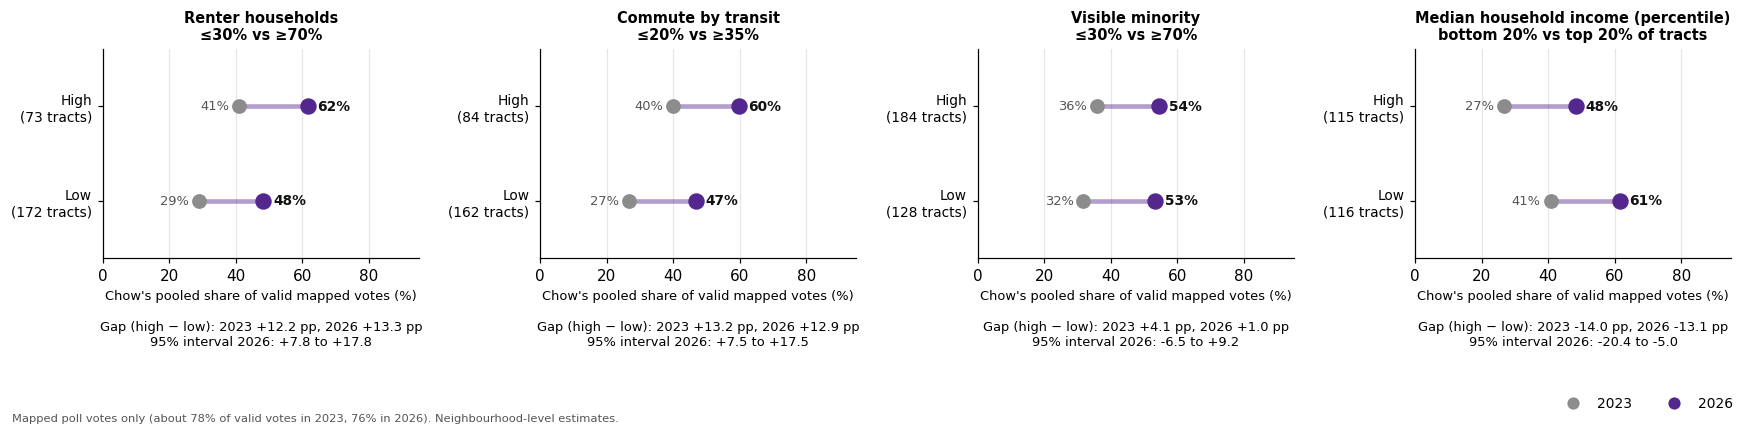

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharex=True)
for a, v in zip(axes, FOCUS_VARS):
    r = ALLC.loc[v]; lo, hi = CONTRAST[v]; u = UNIT[v]
    for yy, (lab, p23, p26, n) in zip((1, 0), ((f"High\n({hi}{u} or more)", r.high23, r.high26, r.n_high), (f"Low\n({lo}{u} or less)", r.low23, r.low26, r.n_low))):
        a.hlines(yy, p23, p26, color=CHOW, lw=3, alpha=.45); a.scatter(p23, yy, color=C23, s=75, zorder=3); a.scatter(p26, yy, color=CHOW, s=95, zorder=4)
        a.text(min(p23, p26) - 3, yy, f"{p23:.0f}%", ha="right", va="center", fontsize=8.5, color="#555"); a.text(max(p23, p26) + 3, yy, f"{p26:.0f}%", ha="left", va="center", fontsize=9, fontweight="bold", color="#111")
    a.set_yticks([1, 0]); a.set_yticklabels([f"High\n({int(r.n_high)} tracts)", f"Low\n({int(r.n_low)} tracts)"], fontsize=9)
    a.set_title(f"{VLAB[v]}\n≤{lo}{u} vs ≥{hi}{u}" if v != "income_pct" else f"{VLAB[v]}\nbottom 20% vs top 20% of tracts", fontsize=9.5)
    a.text(.5, -.30, f"Gap (high − low): 2023 {r.gap23:+.1f} pp, 2026 {r.gap26:+.1f} pp\n95% interval 2026: {r.gap26_lo:+.1f} to {r.gap26_hi:+.1f}", transform=a.transAxes, ha="center", va="top", fontsize=8.5)
    a.set_xlim(0, 95); a.set_ylim(-.6, 1.6); a.set_xlabel("Chow's pooled share of valid mapped votes (%)", fontsize=8.5); a.grid(False, axis="y")
fig.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=C23, ms=9, label="2023"), Line2D([], [], marker="o", color="w", markerfacecolor=CHOW, ms=9, label="2026")], loc="lower right", bbox_to_anchor=(.995, .0), ncol=2, frameon=False, fontsize=9)
foot(fig, .0); plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()

**The four contrasts you asked about.** Chow's pooled share rose by about 20 points in every group, so the gaps hardly changed between elections. **Renters:** in tracts with 70% or more renter households (73 tracts) she took 41% in 2023 and 62% in 2026, against 29% and 48% where 30% or fewer households rent (172 tracts): a gap of **+12.2, then +13.3 points** (95% interval for 2026: +7.8 to +17.8). **Transit commuting:** 35% or more of commuters on transit (84 tracts) against 20% or less (162): **+13.2, then +12.9** (+7.5 to +17.5). **Income:** she did better in the lowest-income tracts than the highest: the top 20% of tracts gave her 27% and 48%, the bottom 20% gave 41% and 61%, a gap of **−14.0, then −13.1** (−20.4 to −5.0). **Visible minority:** tracts that are 70% or more visible minority (184 tracts) against 30% or less (128 tracts) differ little: **+4.1, then +1.0** (−6.5 to +9.2, so no clear difference). The high-minority tracts hold 26% of 2026 mapped votes, the low-minority tracts 23%, so this null result is not a small-group artefact. The near-zero citywide gap is the average of very different patterns in different parts of the city (see below, and the Section 3 heatmaps).

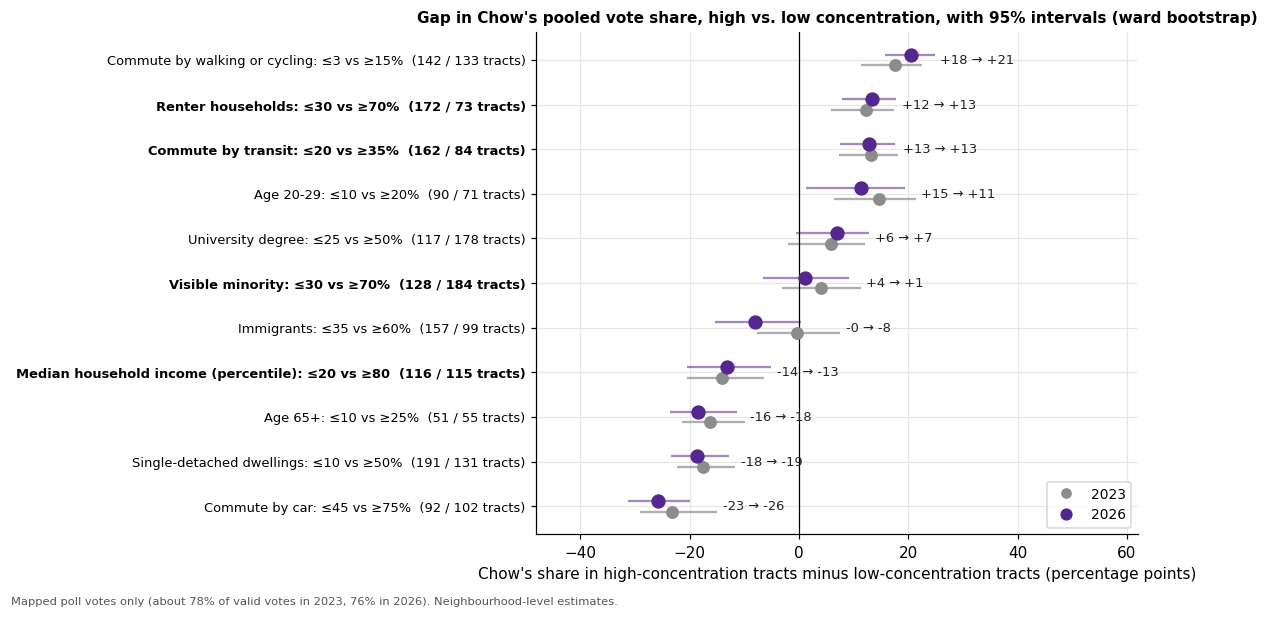

,tracts low,tracts high,low 2023,high 2023,gap 2023,low 2026,high 2026,gap 2026,gap 2026 lo,gap 2026 hi,change in gap,change lo,change hi,% of 2026 votes: low,% of 2026 votes: high
Renter households (30% / 70%),172,73,28.9,41.1,12.2,48.3,61.6,13.3,7.8,17.8,1.1,-1.1,3.4,27.1,12.0
Commute by transit (20% / 35%),162,84,26.8,39.9,13.2,46.8,59.6,12.9,7.5,17.5,-0.3,-2.7,2.0,27.4,14.2
Visible minority (30% / 70%),128,184,31.8,35.9,4.1,53.4,54.4,1.0,-6.5,9.2,-3.0,-5.8,0.0,23.0,26.2
Median household income (percentile) (20 / 80),116,115,40.8,26.8,-14.0,61.4,48.3,-13.1,-20.4,-5.0,0.8,-1.4,2.7,17.8,19.2
Single-detached dwellings (10% / 50%),191,131,42.6,25.0,-17.6,62.9,44.3,-18.6,-23.4,-12.8,-0.9,-2.8,0.8,35.1,20.5
Commute by car (45% / 75%),92,102,48.9,25.8,-23.1,69.4,43.6,-25.8,-31.2,-19.9,-2.7,-5.8,-0.5,19.5,16.5
Commute by walking or cycling (3% / 15%),142,133,28.7,46.3,17.6,47.3,67.8,20.5,15.7,24.8,2.9,0.5,5.7,20.2,27.3
Immigrants (35% / 60%),157,99,36.6,36.1,-0.4,59.3,51.3,-8.0,-15.3,0.4,-7.6,-9.8,-4.1,30.3,13.0
University degree (25% / 50%),117,178,30.0,35.8,5.8,50.5,57.5,6.9,-0.5,12.9,1.1,-1.6,4.3,15.1,35.0
Age 20-29 (10% / 20%),90,71,31.1,45.7,14.6,53.9,65.4,11.4,1.2,19.4,-3.1,-6.2,-0.6,16.0,14.9


In [19]:
D = ALLC.sort_values("gap26")
fig, a = plt.subplots(figsize=(10.5, 5.6)); y = np.arange(len(D))
for yy, (v, r) in zip(y, D.iterrows()):
    a.hlines(yy + .12, r.gap26_lo, r.gap26_hi, color=CHOW, lw=1.5, alpha=.55); a.hlines(yy - .12, r.gap23_lo, r.gap23_hi, color=C23, lw=1.5, alpha=.7)
    a.scatter(r.gap23, yy - .12, color=C23, s=55, zorder=3); a.scatter(r.gap26, yy + .12, color=CHOW, s=70, zorder=4)
    a.text(max(r.gap26_hi, r.gap23_hi) + 1, yy, f"{r.gap23:+.0f} → {r.gap26:+.0f}", va="center", fontsize=8.5, color="#222")
a.axvline(0, color="k", lw=.8); a.set_yticks(y)
a.set_yticklabels([f"{VLAB[v]}: " + (f"≤{CONTRAST[v][0]} vs ≥{CONTRAST[v][1]}" + UNIT[v]) + f"  ({int(r.n_low)} / {int(r.n_high)} tracts)" for v, r in D.iterrows()], fontsize=8.5)
for lab, v in zip(a.get_yticklabels(), D.index):
    if v in FOCUS_VARS: lab.set_fontweight("bold")
a.set(xlabel="Chow's share in high-concentration tracts minus low-concentration tracts (percentage points)", xlim=(-48, 62), title="Gap in Chow's pooled vote share, high vs. low concentration, with 95% intervals (ward bootstrap)")
a.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=C23, ms=8, label="2023"), Line2D([], [], marker="o", color="w", markerfacecolor=CHOW, ms=9, label="2026")], loc="lower right", fontsize=9)
foot(fig); plt.tight_layout(rect=(0, .02, 1, 1)); plt.show()
tab = ALLC[["n_low", "n_high", "low23", "high23", "gap23", "low26", "high26", "gap26", "gap26_lo", "gap26_hi", "dgap", "dgap_lo", "dgap_hi", "pct_votes26_low", "pct_votes26_high"]].copy()
tab.index = [VLAB[v] + f" ({CONTRAST[v][0]}{UNIT[v]} / {CONTRAST[v][1]}{UNIT[v]})" for v in tab.index]
tab.columns = ["tracts low", "tracts high", "low 2023", "high 2023", "gap 2023", "low 2026", "high 2026", "gap 2026", "gap 2026 lo", "gap 2026 hi", "change in gap", "change lo", "change hi", "% of 2026 votes: low", "% of 2026 votes: high"]
with pd.option_context("display.float_format", lambda v: f"{v:,.1f}", "display.width", 250, "display.max_columns", 40): display(tab)

**All eleven contrasts.** The largest gaps are for **car commuting (−23.1, then −25.8; she did far worse where car commuting is common)**, **walking or cycling (+17.6, then +20.5)**, **single-detached housing (−17.6, −18.6)** and **age 65+ (−16.3, −18.4)**; then age 20-29 (+14.6, +11.4), renters (+12.2, +13.3), transit (+13.2, +12.9) and income (−14.0, −13.1). University education (+5.8, +6.9) and visible-minority share (+4.1, +1.0) have gaps whose 95% intervals include zero in 2026, and so do immigrants (−0.4, −8.0; interval −15.3 to +0.4). Only **immigrant share** changed clearly (gap change −7.6 points, interval −9.8 to −4.1: her vote rose less in high-immigrant tracts than in low-immigrant ones); the other changes are small, though the intervals exclude zero for car commuting (−2.7), walking or cycling (+2.9) and age 20-29 (−3.1). So the expansion between 2023 and 2026 mostly kept the *size* of the demographic contrasts, as Section 3 found for the correlations. The groups are also not small slices: the groups hold between 9% and 35% of 2026 mapped votes (the last two columns of the table). The intervals use 25 ward clusters, so they are approximate, and the gaps are differences between neighbourhood groups, which also differ in many other ways (renters, transit, density and incomes overlap in the same parts of the city).

### Sensitivity to the cutoffs

The cutoffs above are round numbers chosen for readability. As a check, the same contrast with **the bottom and top 20% of tracts** for every variable (cutoffs set at the 20th and 80th percentiles of the tract distribution, so each group has about 117 tracts).

In [20]:
rows = []
for v in tqdm(CONTRAST, desc="quintile contrasts", leave=False):
    x = pd.Series(LEVEL[v]).dropna(); cuts = (x.quantile(.2), x.quantile(.8)); q = contrast(v, REGIONS["All tracts"], cuts=cuts)
    rows.append({"variable": VLAB[v], "chosen cutoffs": f"{CONTRAST[v][0]} / {CONTRAST[v][1]}{UNIT[v]}", "gap 2023": ALLC.loc[v, "gap23"], "gap 2026": ALLC.loc[v, "gap26"],
                 "quintile cutoffs": f"{cuts[0]:.0f} / {cuts[1]:.0f}{UNIT[v]}", "tracts (low/high)": f"{q['n_low']}/{q['n_high']}", "quintile gap 2023": q["gap23"], "quintile gap 2026": q["gap26"], "interval 2026": f"{q['gap26_lo']:+.1f} to {q['gap26_hi']:+.1f}"})
SENS = pd.DataFrame(rows).set_index("variable")
with pd.option_context("display.float_format", lambda v: f"{v:+.1f}", "display.width", 250, "display.max_columns", 40): display(SENS)

,chosen cutoffs,gap 2023,gap 2026,quintile cutoffs,tracts (low/high),quintile gap 2023,quintile gap 2026,interval 2026
variable,,,,,,,,
Renter households,30 / 70%,+12.2,+13.3,24 / 63%,117/118,+12.5,+14.8,+8.7 to +19.8
Commute by transit,20 / 35%,+13.2,+12.9,18 / 33%,117/118,+13.9,+14.0,+8.3 to +19.1
Visible minority,30 / 70%,+4.1,+1.0,28 / 79%,117/117,+6.6,+2.4,-5.3 to +10.6
Median household income (percentile),20 / 80,-14.0,-13.1,20 / 80,119/123,-13.6,-12.9,-20.4 to -4.9
Single-detached dwellings,10 / 50%,-17.6,-18.6,2 / 53%,117/117,-17.3,-18.5,-23.5 to -11.4
Commute by car,45 / 75%,-23.1,-25.8,48 / 74%,117/117,-22.0,-24.3,-29.6 to -18.3
Commute by walking or cycling,3 / 15%,+17.6,+20.5,3 / 16%,117/117,+20.0,+22.0,+17.4 to +26.6
Immigrants,35 / 60%,-0.4,-8.0,31 / 59%,117/117,+0.6,-6.9,-14.8 to +3.0
University degree,25 / 50%,+5.8,+6.9,25 / 57%,117/118,+5.3,+7.0,-0.3 to +13.2


The conclusions do not depend on the round-number cutoffs: using the bottom and top 20% of tracts, the gaps in 2026 are renters +14.8, transit +14.0, income −12.9, visible minority +2.4 (interval −5.3 to +10.6), car commuting −24.3, walking or cycling +22.0, detached housing −18.5, age 65+ −16.2, age 20-29 +9.4, university +7.0 and immigrants −6.9 (interval −14.8 to +3.0), all within about 3 points of the main results and with the same signs.

### Does the gap hold inside Old Toronto and the suburbs?

The same contrast within Old Toronto and within the suburbs. Citywide gaps can partly reflect the difference *between* the two (for example, renters and visible minorities are not spread the same way in both). Contrasts with fewer than 15 tracts in either group are left blank.

,All tracts: gap 2023,All tracts: gap 2026,All tracts: tracts (low/high),Old Toronto: gap 2023,Old Toronto: gap 2026,Old Toronto: tracts (low/high),Suburbs: gap 2023,Suburbs: gap 2026,Suburbs: tracts (low/high)
variable,,,,,,,,,
Renter households,+12.2,+13.3,172/73,+15.7,+11.5,23/28,+5.5,+8.2,149/45
Commute by transit,+13.2,+12.9,162/84,+13.1,+10.3,30/32,+10.0,+9.6,132/52
Visible minority,+4.1,+1.0,128/184,NaN,NaN,75/6,+13.3,+12.1,53/178
Median household income (percentile),-14.0,-13.1,116/115,-18.9,-15.0,36/42,-10.7,-11.3,80/73
Single-detached dwellings,-17.6,-18.6,191/131,NaN,NaN,102/13,-8.9,-9.2,89/118
Commute by car,-23.1,-25.8,92/102,NaN,NaN,86/0,NaN,NaN,6/102
Commute by walking or cycling,+17.6,+20.5,142/133,NaN,NaN,0/127,NaN,NaN,142/6
Immigrants,-0.4,-8.0,157/99,NaN,NaN,105/0,+11.3,+4.4,52/99
University degree,+5.8,+6.9,117/178,NaN,NaN,3/115,-4.4,-6.8,114/63


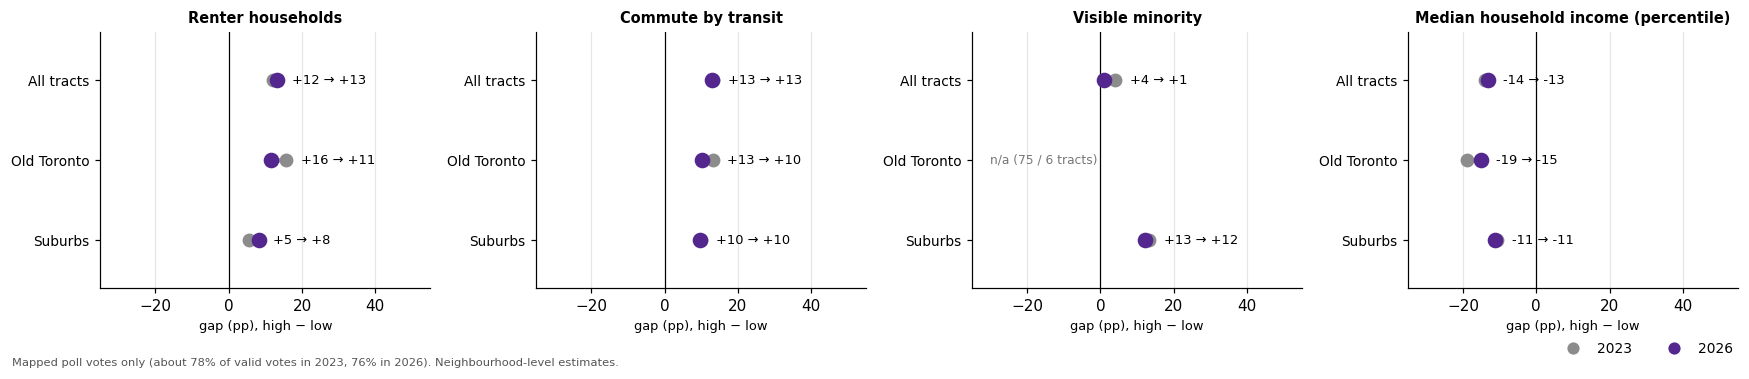

In [21]:
G2 = CON.assign(v=CON.variable.map(VLAB)).pivot(index="variable", columns="region", values=["gap23", "gap26", "n_low", "n_high"]).reindex(list(CONTRAST))
tab = pd.DataFrame({"variable": [VLAB[v] for v in G2.index]}).set_index("variable")
for rname in REGIONS:
    tab[f"{rname}: gap 2023"] = G2[("gap23", rname)].values; tab[f"{rname}: gap 2026"] = G2[("gap26", rname)].values
    tab[f"{rname}: tracts (low/high)"] = [f"{int(l)}/{int(h)}" for l, h in zip(G2[("n_low", rname)], G2[("n_high", rname)])]
with pd.option_context("display.float_format", lambda v: f"{v:+.1f}", "display.width", 250, "display.max_columns", 40): display(tab)
fig, axes = plt.subplots(1, len(FOCUS_VARS), figsize=(16, 3.4), sharex=True)
for a, v in zip(axes, FOCUS_VARS):
    for yy, rname in zip((2, 1, 0), REGIONS):
        r = CON[(CON.variable == v) & (CON.region == rname)].iloc[0]
        if pd.isna(r.get("gap26")):
            a.text(-30, yy, f"n/a ({int(r.n_low)} / {int(r.n_high)} tracts)", va="center", fontsize=8, color="#777"); continue
        a.hlines(yy, r.gap23, r.gap26, color=CHOW, lw=3, alpha=.45); a.scatter(r.gap23, yy, color=C23, s=65, zorder=3); a.scatter(r.gap26, yy, color=CHOW, s=85, zorder=4)
        a.text(max(r.gap23, r.gap26) + 4, yy, f"{r.gap23:+.0f} → {r.gap26:+.0f}", va="center", fontsize=8.5)
    a.axvline(0, color="k", lw=.8); a.set_yticks([2, 1, 0]); a.set_yticklabels(list(REGIONS), fontsize=9); a.set_ylim(-.6, 2.6); a.set_title(VLAB[v], fontsize=9.5); a.set_xlim(-35, 55); a.set_xlabel("gap (pp), high − low", fontsize=8.5); a.grid(False, axis="y")
fig.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=C23, ms=9, label="2023"), Line2D([], [], marker="o", color="w", markerfacecolor=CHOW, ms=9, label="2026")], loc="lower right", bbox_to_anchor=(.995, .0), ncol=2, frameon=False, fontsize=9)
foot(fig, .0); plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()

**Inside Old Toronto and the suburbs.** The renter, transit and income contrasts hold within both parts of the city, but they are **smaller in the suburbs for renters and income**: renters +15.7 → +11.5 in Old Toronto against +5.5 → +8.2 in the suburbs; income −18.9 → −15.0 against −10.7 → −11.3; transit +13.1 → +10.3 against +10.0 → +9.6. Over time the renter gap narrowed in Old Toronto and widened in the suburbs, so the citywide +12.2 → +13.3 hides two different movements. **Visible minority is where the geography matters most.** Old Toronto has too few highly visible-minority tracts (6) for a contrast, but **in the suburbs Chow did 13.3 points better (2023) and 12.1 points better (2026) in tracts that are 70% or more visible minority** (178 tracts) than in those that are 30% or less (53 tracts), though citywide the gap is about zero: the citywide figure partly compares Old Toronto's low-minority, high-Chow tracts with suburban high-minority, lower-Chow tracts, which is a difference between parts of the city rather than between neighbourhoods like each other. Contrasts where one part of the city lacks one of the groups (car and walking or cycling in the suburbs, for example) are left blank. Among the suburbs, immigrant share has a contrast that shrinks from +11.3 to +4.4, the same shift the Scarborough correlations showed.

## 5. What the newly leading tracts look like, and where Chow's votes were recorded

### 5.1 Profile of the three main groups

For six measures, the **median tract** in each group (large dot, labelled) and the **middle half** of tracts (light bar), in familiar units. Income is a tract **percentile** (0 = lowest, 100 = highest) because dollar levels are not documented well enough to interpret directly. Medians of tracts are the typical tract in each group, not the median of the combined area.

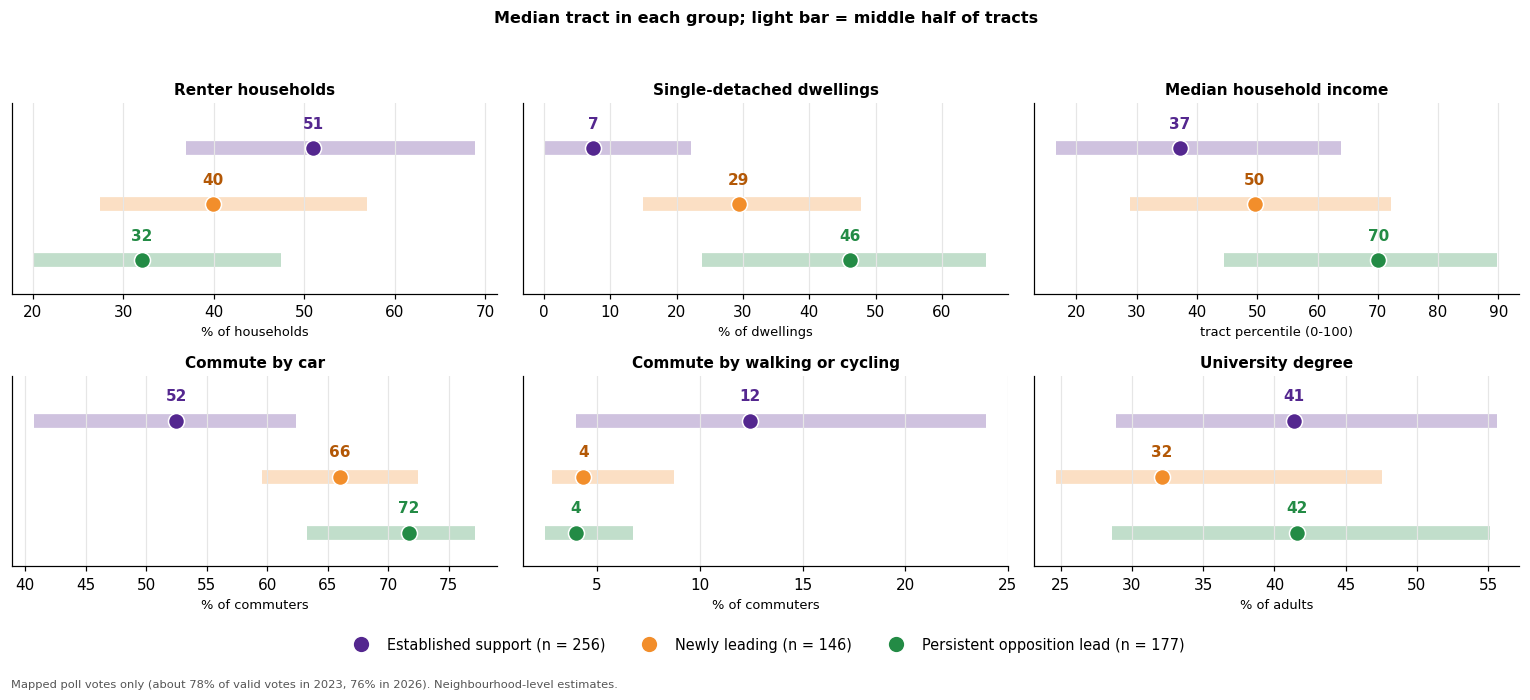

Visible minority and immigrant shares (median tract, %):


,Established support,Newly leading,Persistent opposition lead
Visible minority,54.9,58.2,44.8
Immigrants,44.0,49.1,46.9
Age 65+,14.1,16.9,18.7
Age 20-29,14.7,13.6,12.5


In [22]:
def pvals(c):
    return t[c] if c == "income_pct" else t[c] * CENSUS[c][2]
PLAB = {"income_pct": ("Median household income", "tract percentile (0-100)")}; PLAB.update({c: (CENSUS[c][0], CENSUS[c][1]) for c in CENSUS})
fig, axes = plt.subplots(2, 3, figsize=(14, 6.2))
for a, c in zip(axes.ravel(), PROFILE_VARS):
    v = pvals(c)
    for yy, g in zip((2, 1, 0), MAIN):
        x = v[t.group == g].dropna(); q1, med, q3 = x.quantile([.25, .5, .75])
        a.hlines(yy, q1, q3, color=GROUP_COLOURS[g], lw=9, alpha=.28, zorder=1); a.scatter(med, yy, color=GROUP_COLOURS[g], s=110, zorder=3, edgecolor="white", linewidth=1)
        a.text(med, yy + .36, f"{med:.0f}", ha="center", fontsize=10, fontweight="bold", color=GROUP_COLOURS[g] if g != "Newly leading" else "#b35806")
    a.set_yticks([])
    a.set_ylim(-.6, 2.8); a.set_title(PLAB[c][0], fontsize=10); a.set_xlabel(PLAB[c][1], fontsize=8.5); a.grid(False, axis="y")
fig.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=GROUP_COLOURS[g], ms=11, label=f"{g} (n = {int((t.group == g).sum())})") for g in MAIN], loc="lower center", bbox_to_anchor=(.5, .035), ncol=3, frameon=False, fontsize=9.5)
fig.suptitle("Median tract in each group; light bar = middle half of tracts", fontsize=10.5, fontweight="bold", y=.995); foot(fig, .0); plt.tight_layout(rect=(0, .09, 1, .96)); plt.show()
print("Visible minority and immigrant shares (median tract, %):"); display(pd.DataFrame({g: {CENSUS[c][0]: (t.loc[t.group == g, c] * 100).median() for c in ("vminvisi_pct", "imstimmi_pct", "agec065p_pct", "agec2029_pct")} for g in MAIN}).round(1))

**What newly leading tracts look like.** The median newly leading tract sits between the established and persistent-opposition tracts on renters (40% of households, vs. 51% and 32%), single-detached housing (29%, vs. 7% and 46%) and income (percentile 50, vs. 37 and 70). On how people commute it is close to the persistent-opposition tracts: 66% by car (52% established, 72% persistent opposition) and 4% walking or cycling (12% established, 4% persistent). And it is *different from both* on education and migration: a median 32% with a university degree (41% and 42%), a visible-minority share of 58% (55% and 45%) and an immigrant share of 49% (44% and 47%). The light bars show that the groups overlap on most measures, so "between" describes medians, not clean separation.

### 5.2 Did the kinds of places supplying Chow's votes change?

For four characteristics, the **vote-weighted average of the tract characteristic**, using Chow's mapped vote count in each tract as the weight, in 2023 and 2026 (purple). The grey-outlined dots use **all valid mapped votes** as weights on the same tracts, a benchmark for the places supplying votes overall. Each row uses a common set of tracts across both years (tracts with missing data on that characteristic are dropped). These summarize the places where her votes were recorded; the census describes residents and households, and the calculation says nothing about the tenure, commuting or income of her voters.

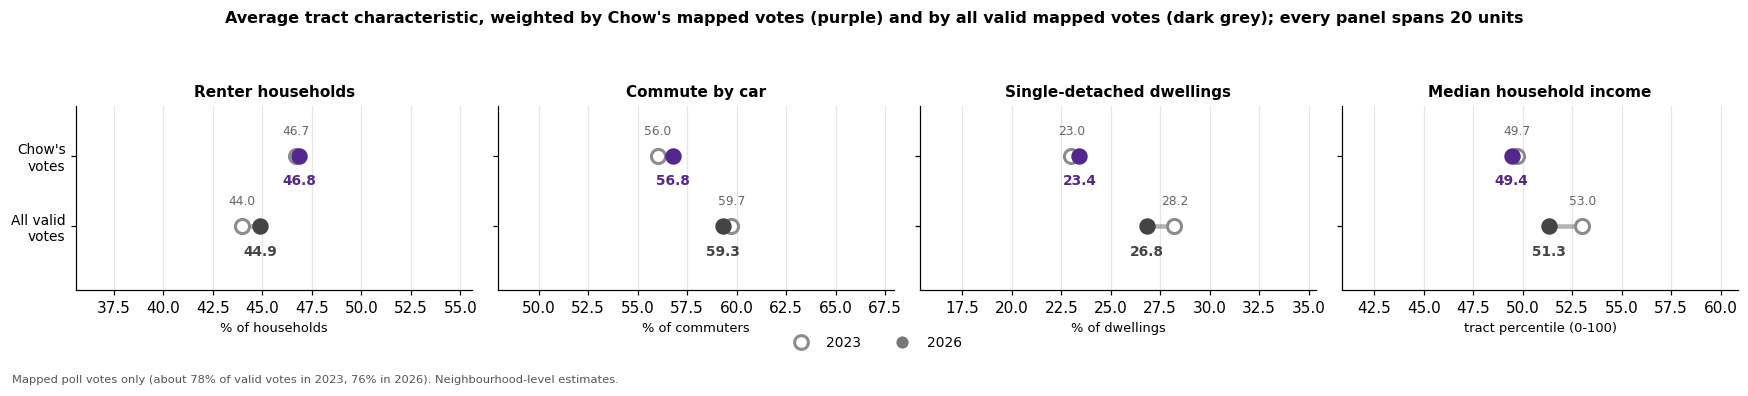

,tracts,Chow-weighted 2023,Chow-weighted 2026,change,all-votes-weighted 2023,all-votes-weighted 2026,change (all votes)
measure,,,,,,,
Renter households,583,46.7,46.8,0.1,44.0,44.9,0.9
Commute by car,583,56.0,56.8,0.7,59.7,59.3,-0.4
Single-detached dwellings,585,23.0,23.4,0.4,28.2,26.8,-1.4
Median household income,583,49.7,49.4,-0.3,53.0,51.3,-1.7


In [23]:
rows = []
fig, axes = plt.subplots(1, len(WEIGHTED_VARS), figsize=(16, 3.4))
for a, c in zip(axes, WEIGHTED_VARS):
    d = t.dropna(subset=[c]); v = d[c] if c == "income_pct" else d[c] * CENSUS[c][2]
    w = {"chow": (np.average(v, weights=d.chow_v23), np.average(v, weights=d.chow_v26)), "all": (np.average(v, weights=d.valid23), np.average(v, weights=d.valid26))}
    rows.append({"measure": PLAB[c][0], "tracts": len(d), "Chow-weighted 2023": w["chow"][0], "Chow-weighted 2026": w["chow"][1], "change": w["chow"][1] - w["chow"][0],
                 "all-votes-weighted 2023": w["all"][0], "all-votes-weighted 2026": w["all"][1], "change (all votes)": w["all"][1] - w["all"][0]})
    for yy, (key, colr, lab) in zip((1, 0), (("chow", CHOW, "Weighted by Chow's votes"), ("all", "#444444", "Weighted by all valid votes"))):
        a.hlines(yy, *w[key], color=colr, lw=3, alpha=.4); a.scatter(w[key][0], yy, color="white", edgecolor=C23, linewidth=2, s=85, zorder=3); a.scatter(w[key][1], yy, color=colr, s=95, zorder=4)
        a.text(w[key][0], yy + .3, f"{w[key][0]:.1f}", ha="center", fontsize=8, color="#666"); a.text(w[key][1], yy - .42, f"{w[key][1]:.1f}", ha="center", fontsize=9, fontweight="bold", color=colr)
    a.set_yticks([1, 0]); a.set_yticklabels(["Chow's\nvotes", "All valid\nvotes"] if a is axes[0] else [""] * 2, fontsize=9); mid = np.mean([w["chow"][0], w["chow"][1], w["all"][0], w["all"][1]]); a.set_xlim(mid - 10, mid + 10)   # same 20-unit width in every panel so small changes look small
    a.set_ylim(-.9, 1.7); a.set_title(PLAB[c][0], fontsize=10); a.set_xlabel(PLAB[c][1], fontsize=8.5); a.grid(False, axis="y")
fig.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor="white", markeredgecolor=C23, markeredgewidth=2, ms=9, label="2023"), Line2D([], [], marker="o", color="w", markerfacecolor="#777", ms=9, label="2026")], loc="lower center", bbox_to_anchor=(.5, .06), ncol=2, frameon=False, fontsize=9)
fig.suptitle("Average tract characteristic, weighted by Chow's mapped votes (purple) and by all valid mapped votes (dark grey); every panel spans 20 units", fontsize=10.5, fontweight="bold", y=1.0)
foot(fig, .0); plt.tight_layout(rect=(0, .09, 1, .93)); plt.show()
display(pd.DataFrame(rows).set_index("measure").round(1))

**Did the places supplying Chow's votes change?** Barely. Weighted by her votes, the average tract characteristic moved by less than one point between 2023 and 2026: renter share 46.7 → 46.8, car commuting 56.0 → 56.8, single-detached 23.0 → 23.4, income percentile 49.7 → 49.4. The all-votes benchmark moved slightly more (detached 28.2 → 26.8, income percentile 53.0 → 51.3), and the gap between the places supplying Chow's votes and those supplying votes overall narrowed by one to two points (renters +2.7 → +1.9, car −3.7 → −2.5, detached −5.2 → −3.4, income percentile −3.3 → −1.9). Her vote came from a slightly more typical set of places, but not a different kind: the geographic spread in the map happened within the existing neighbourhood divides. These are averages of tract characteristics weighted by votes, not the characteristics of her voters.

### 5.3 Profile of the added votes themselves

Section 5.2 asked whether the places supplying *all* of Chow's votes changed. This asks about the **new votes**: the characteristic of each tract is averaged using as weight the votes she **added** there between 2023 and 2026 (her 2026 mapped votes minus her 2023 mapped votes). Because the weights add up (2023 votes + added votes = 2026 votes), the 2026 average is a blend of the 2023 average and the added-votes average, and the added votes are 52.6% of her 2026 mapped votes. So the added-votes average shows what the *marginal* places looked like, and its difference from the 2023 average shows how much the mix could have changed. One tract lost 23 Chow votes; it is kept (signed weights) so the weights sum exactly to her net increase of 215,705. The grey diamond shows where **all candidates'** valid mapped votes grew (the growth of the electorate in mapped votes), as a reference. Intervals come from the ward bootstrap used in Section 4. These are averages of **tract** characteristics weighted by votes, not characteristics of the people who cast the added votes.

In [24]:
t["add_chow"] = t.chow_v26 - t.chow_v23; t["add_valid"] = t.valid26 - t.valid23
assert np.isclose(t.add_chow.sum(), t.chow_v26.sum() - t.chow_v23.sum())
print(f"Added Chow votes: {t.add_chow.sum():,.0f} = {t.add_chow.sum() / t.chow_v26.sum() * 100:.1f}% of her 2026 mapped votes | tracts with fewer Chow votes: {int((t.add_chow < 0).sum())} ({t.add_chow[t.add_chow < 0].sum():,.0f}) | tracts with fewer valid votes: {int((t.add_valid < 0).sum())}")
SERIES = {"base": "chow_v23", "plus": "add_chow", "now": "chow_v26", "val": "add_valid", "val23": "valid23"}

def boot_wavg(x, ok, w):
    num, den = np.bincount(wi, weights=w * x * ok, minlength=len(W)), np.bincount(wi, weights=w * ok, minlength=len(W))
    return num.sum() / den.sum(), num[draws].sum(1) / den[draws].sum(1)

rows = []
for v in tqdm(CONTRAST, desc="added-vote profiles", leave=False):
    x = LEVEL[v].copy(); ok = (~np.isnan(x)).astype(float); x = np.nan_to_num(x)
    est = {k: boot_wavg(x, ok, t[c].values)[0] for k, c in SERIES.items()}
    _, bb = boot_wavg(x, ok, t.chow_v23.values); _, ba = boot_wavg(x, ok, t.add_chow.values)
    assert np.isclose(est["base"] * (t.chow_v23.values * ok).sum() + est["plus"] * (t.add_chow.values * ok).sum(), est["now"] * (t.chow_v26.values * ok).sum())
    d = ba - bb
    rows.append({"variable": v, **est, "diff": est["plus"] - est["base"], "lo": np.nanpercentile(d, 2.5), "hi": np.nanpercentile(d, 97.5)})
AP = pd.DataFrame(rows).set_index("variable")
tab = AP.rename(columns={"base": "Chow 2023 votes", "plus": "added Chow votes", "now": "Chow 2026 votes", "val": "added valid votes (all)", "val23": "all valid votes 2023", "diff": "added − 2023", "lo": "interval lo", "hi": "interval hi"})
tab.index = [VLAB[v] + (" (pctile)" if v == "income_pct" else " (%)") for v in AP.index]
with pd.option_context("display.float_format", lambda v: f"{v:,.1f}", "display.width", 250, "display.max_columns", 40): display(tab)

Added Chow votes: 215,705 = 52.6% of her 2026 mapped votes | tracts with fewer Chow votes: 1 (-23) | tracts with fewer valid votes: 8


,Chow 2023 votes,added Chow votes,Chow 2026 votes,added valid votes (all),all valid votes 2023,added − 2023,interval lo,interval hi
Renter households (%),46.7,47.0,46.8,47.7,44.0,0.3,-0.9,1.5
Commute by transit (%),26.3,26.0,26.1,26.3,25.1,-0.3,-0.7,0.2
Visible minority (%),49.8,51.8,50.9,56.6,49.2,2.0,-0.0,3.8
Median household income (percentile) (pctile),49.7,49.2,49.4,46.2,53.0,-0.5,-1.8,0.8
Single-detached dwellings (%),23.0,23.8,23.4,22.6,28.2,0.8,-0.6,2.1
Commute by car (%),56.0,57.4,56.8,58.1,59.7,1.4,0.2,2.5
Commute by walking or cycling (%),14.0,12.9,13.5,12.2,11.5,-1.1,-1.9,-0.2
Immigrants (%),42.6,43.5,43.1,46.5,43.1,0.9,-0.3,1.9
University degree (%),44.2,43.2,43.7,41.6,43.3,-1.0,-2.3,0.4
Age 20-29 (%),15.2,15.6,15.4,16.3,14.4,0.4,-0.0,0.8


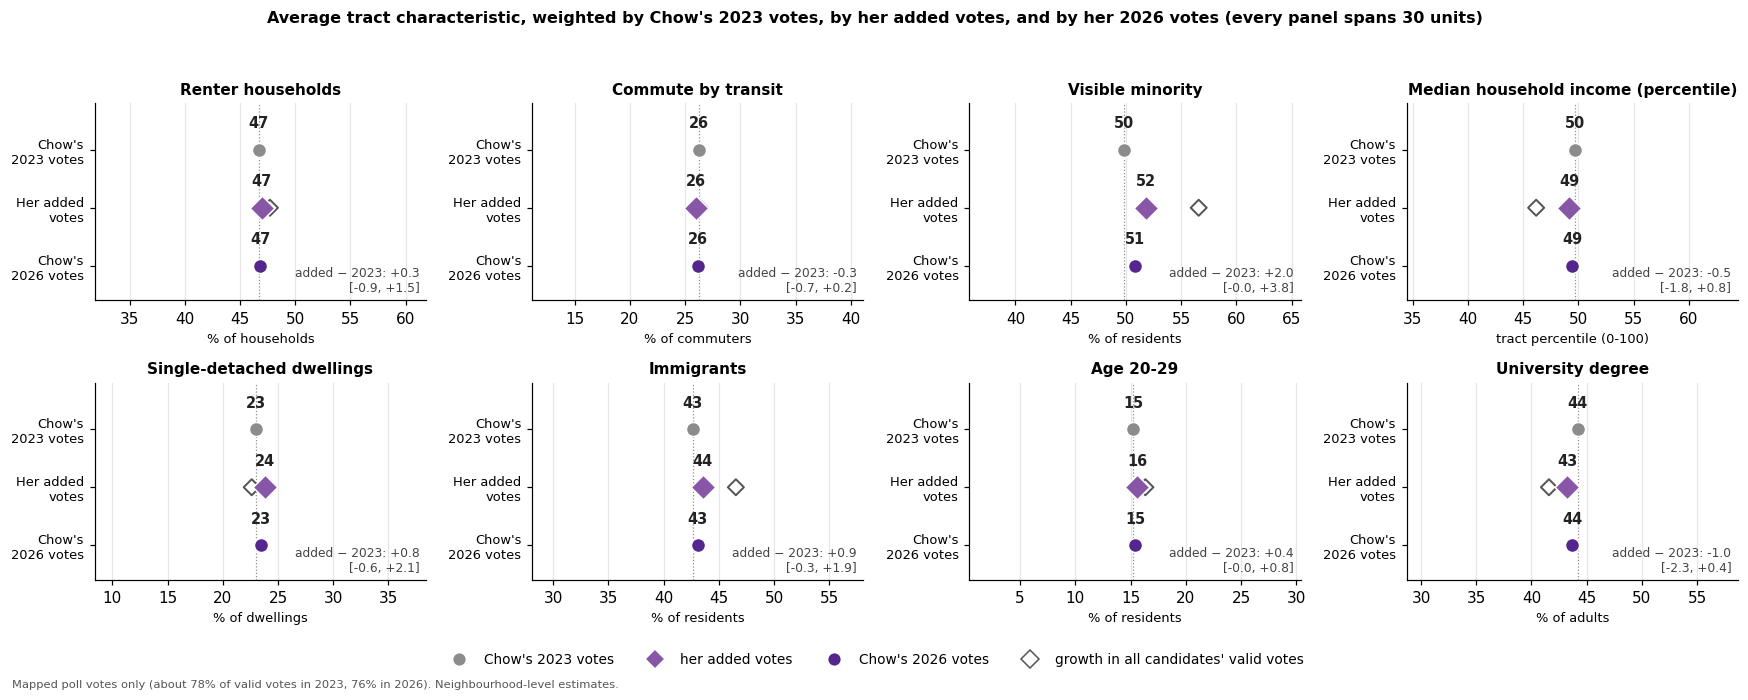

In [25]:
SHOW = ["hhtnrent_pct", "jwmdtran_pct", "vminvisi_pct", "income_pct", "dwtpsdet_pct", "imstimmi_pct", "agec2029_pct", "edcauniv_pct"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.2))
for a, v in zip(axes.ravel(), SHOW):
    r = AP.loc[v]; mid = np.mean([r.base, r.plus, r.now])
    for yy, (val, lab, kw) in zip((2, 1, 0), ((r.base, "Chow's\n2023 votes", dict(color=C23, s=85, marker="o")), (r.plus, "Her added\nvotes", dict(color="#8856a7", s=130, marker="D")), (r.now, "Chow's\n2026 votes", dict(color=CHOW, s=85, marker="o")))):
        a.scatter(val, yy, zorder=4, edgecolor="white", linewidth=1, **kw); a.text(val, yy + .38, f"{val:.0f}", ha="center", fontsize=9.5, fontweight="bold", color="#222")
    a.scatter(r.val, 1, marker="D", s=55, facecolor="none", edgecolor="#555", linewidth=1.3, zorder=3)
    a.axvline(r.base, color=C23, lw=.8, ls=":", zorder=1)
    a.set_yticks([2, 1, 0]); a.set_yticklabels(["Chow's\n2023 votes", "Her added\nvotes", "Chow's\n2026 votes"], fontsize=8.5); a.set_xlim(mid - 15, mid + 15); a.set_ylim(-.6, 2.8)
    a.set_title(VLAB[v], fontsize=10); a.set_xlabel("tract percentile (0-100)" if v == "income_pct" else CENSUS[v][1], fontsize=8.5); a.grid(False, axis="y")
    a.text(.98, .03, f"added − 2023: {r['diff']:+.1f}\n[{r.lo:+.1f}, {r.hi:+.1f}]", transform=a.transAxes, ha="right", va="bottom", fontsize=8, color="#444")
fig.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=C23, ms=9, label="Chow's 2023 votes"), Line2D([], [], marker="D", color="w", markerfacecolor="#8856a7", ms=9, label="her added votes"), Line2D([], [], marker="o", color="w", markerfacecolor=CHOW, ms=9, label="Chow's 2026 votes"), Line2D([], [], marker="D", color="w", markerfacecolor="none", markeredgecolor="#555", ms=8, label="growth in all candidates' valid votes")], loc="lower center", bbox_to_anchor=(.5, .015), ncol=4, frameon=False, fontsize=9)
fig.suptitle("Average tract characteristic, weighted by Chow's 2023 votes, by her added votes, and by her 2026 votes (every panel spans 30 units)", fontsize=10.5, fontweight="bold", y=.995)
foot(fig, .0); plt.tight_layout(rect=(0, .07, 1, .96)); plt.show()

**The added votes came from places like the ones that already supported her.** Weighted by her added votes, the average tract has 47.0% renter households (2023 votes: 46.7%; interval for the difference −0.9 to +1.5), 26.0% transit commuters (26.3%), 23.8% single-detached dwellings (23.0%), an income percentile of 49.2 (49.7), 15.6% aged 20-29 (15.2%) and 43.2% university-educated adults (44.2%). Only a few differences are distinguishable from zero, and they are small: **car commuting +1.4 points** (57.4% vs. 56.0%; +0.2 to +2.5), **walking or cycling −1.1** (12.9% vs. 14.0%; −1.9 to −0.2), and **visible minority share +2.0** (51.8% vs. 49.8%; −0.0 to +3.8, borderline). So the marginal votes were not concentrated in renter-heavy, younger or lower-income tracts compared with her existing support; if anything they came from slightly more car-oriented and slightly more visible-minority places. The grey diamonds show where **all candidates'** valid mapped votes grew: these grew more in lower-income tracts (income percentile 46.2 against 53.0 for 2023 votes overall) and in tracts with higher visible-minority shares (56.6% against 49.2%), and her added votes sit between her base and that pattern. This shows only where mapped votes grew, and mapped coverage (78% in 2023, 76% in 2026) differs between elections, so it is a pointer for follow-up and not a result.

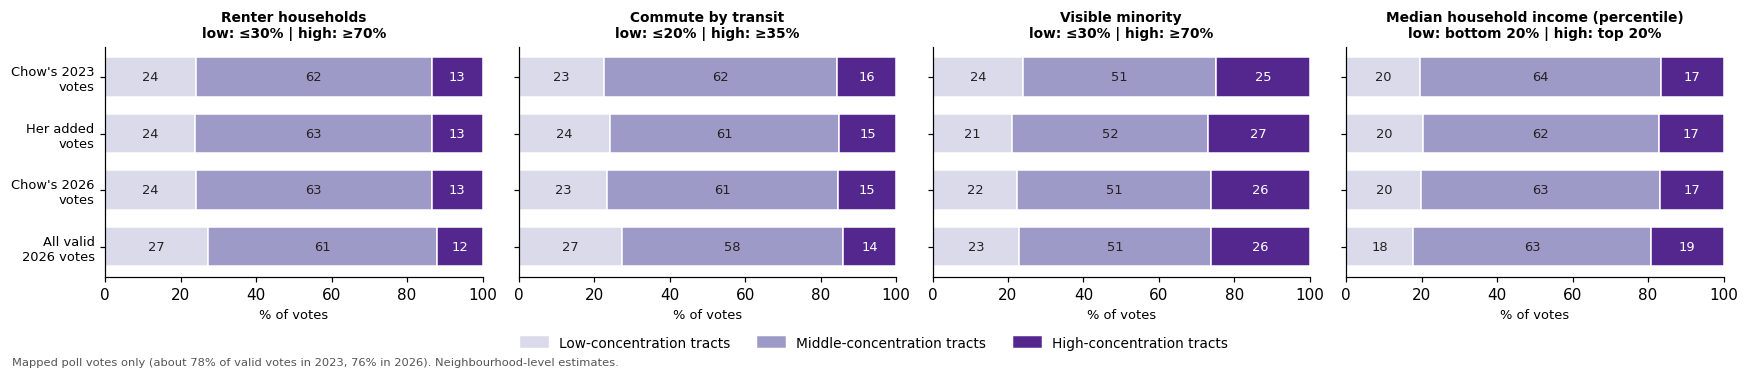

,tracts low/middle/high,base: Low,base: Middle,base: High,add: Low,add: Middle,add: High,now: Low,now: Middle,now: High,all26: Low,all26: Middle,all26: High
variable,,,,,,,,,,,,,
Renter households,172/338/73,24.0,62.5,13.5,23.9,62.6,13.5,23.9,62.6,13.5,27.1,60.9,12.0
Commute by transit,162/337/84,22.5,61.8,15.7,24.2,60.6,15.2,23.4,61.1,15.4,27.4,58.4,14.2
Visible minority,128/271/184,24.0,51.1,24.9,21.1,51.8,27.1,22.5,51.4,26.1,23.0,50.7,26.2
Median household income (percentile),116/352/115,19.5,63.8,16.7,20.3,62.4,17.2,19.9,63.1,17.0,17.8,63.0,19.2


In [26]:
# Where the added votes sat: low / middle / high tracts on the Section 4 cutoffs, as a share of each vote total
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharex=True)
BCOLS = {"Low": "#dadaeb", "Middle": "#9e9ac8", "High": "#54278f"}; split_rows = []
for a, v in zip(axes, FOCUS_VARS):
    lo, hi = CONTRAST[v]; x = LEVEL[v]; ok = ~np.isnan(x); grp = np.where(x <= lo, "Low", np.where(x >= hi, "High", "Middle"))
    shares = {}
    for key, col in (("base", "chow_v23"), ("add", "add_chow"), ("now", "chow_v26"), ("all26", "valid26")):
        w = t[col].values * ok; shares[key] = {g: w[grp == g].sum() / w.sum() * 100 for g in BCOLS}
    split_rows.append({"variable": VLAB[v], "tracts low/middle/high": "/".join(str(int(((grp == g) & ok).sum())) for g in BCOLS), **{f"{k}: {g}": shares[k][g] for k in shares for g in BCOLS}})
    for yy, (key, lab) in zip((3, 2, 1, 0), (("base", "Chow's 2023 votes"), ("add", "Her added votes"), ("now", "Chow's 2026 votes"), ("all26", "All valid 2026 votes"))):
        left = 0
        for g in BCOLS:
            a.barh(yy, shares[key][g], left=left, color=BCOLS[g], edgecolor="white", height=.7)
            if shares[key][g] > 6: a.text(left + shares[key][g] / 2, yy, f"{shares[key][g]:.0f}", ha="center", va="center", fontsize=8.5, color="white" if g == "High" else "#222")
            left += shares[key][g]
    a.set_yticks([3, 2, 1, 0]); a.set_yticklabels(["Chow's 2023\nvotes", "Her added\nvotes", "Chow's 2026\nvotes", "All valid\n2026 votes"] if a is axes[0] else [""] * 4, fontsize=8.5)
    a.set_title(VLAB[v] + (f"\nlow: bottom 20% | high: top 20%" if v == "income_pct" else f"\nlow: ≤{lo}% | high: ≥{hi}%"), fontsize=9); a.set_xlim(0, 100); a.set_xlabel("% of votes", fontsize=8.5); a.grid(False)
fig.legend(handles=[Patch(color=BCOLS[g], label=f"{g}-concentration tracts") for g in BCOLS], loc="lower center", bbox_to_anchor=(.5, .015), ncol=3, frameon=False, fontsize=9)
foot(fig, .0); plt.tight_layout(rect=(0, .08, 1, 1)); plt.show()
with pd.option_context("display.float_format", lambda v: f"{v:,.1f}", "display.width", 250, "display.max_columns", 40): display(pd.DataFrame(split_rows).set_index("variable"))

**Where the added votes sat, by concentration.** In tracts with 70% or more renter households (73 tracts), 13.5% of her 2023 votes and 13.5% of her added votes came from them, against 12.0% of all 2026 valid votes: her new votes were distributed across renter-concentration groups as her old votes were. The same holds for transit commuting (high-transit tracts: 15.7% of 2023 votes, 15.2% of added votes) and for income (bottom 20% of tracts: 19.5% and 20.3%; top 20%: 16.7% and 17.2%). Visible minority is the only variable with a visible shift: tracts that are 70% or more visible minority supplied 24.9% of her 2023 votes and 27.1% of her added votes, and tracts that are 30% or less supplied 24.0% and 21.1%. The renter gap in Section 4 (+13 points) describes the level of her vote in these groups; it does not mean the *added* votes came disproportionately from renter tracts, since she gained about 20 points in all of them.

In [27]:
# The same weighted averages inside Old Toronto and inside the suburbs
rows = []
for v in CONTRAST:
    x = LEVEL[v]; ok = ~np.isnan(x); row = {"variable": VLAB[v]}
    for rname, rm in (("Old Toronto", ~t.suburb.values), ("Suburbs", t.suburb.values)):
        m = ok & rm; row[f"{rname}: 2023 votes"] = np.average(x[m], weights=t.chow_v23.values[m]); row[f"{rname}: added votes"] = np.average(x[m], weights=t.add_chow.values[m]); row[f"{rname}: 2026 votes"] = np.average(x[m], weights=t.chow_v26.values[m])
    rows.append(row)
RG = pd.DataFrame(rows).set_index("variable")
print(f"Share of her added votes: Old Toronto {t.add_chow[~t.suburb].sum() / t.add_chow.sum() * 100:.1f}%, suburbs {t.add_chow[t.suburb].sum() / t.add_chow.sum() * 100:.1f}% | share of 2026 valid mapped votes: Old Toronto {t.valid26[~t.suburb].sum() / t.valid26.sum() * 100:.1f}%, suburbs {t.valid26[t.suburb].sum() / t.valid26.sum() * 100:.1f}%")
with pd.option_context("display.float_format", lambda v: f"{v:,.1f}", "display.width", 250, "display.max_columns", 40): display(RG)

Share of her added votes: Old Toronto 40.9%, suburbs 59.1% | share of 2026 valid mapped votes: Old Toronto 36.2%, suburbs 63.8%


,Old Toronto: 2023 votes,Old Toronto: added votes,Old Toronto: 2026 votes,Suburbs: 2023 votes,Suburbs: added votes,Suburbs: 2026 votes
variable,,,,,,
Renter households,54.0,54.5,54.3,40.3,41.8,41.1
Commute by transit,27.8,27.4,27.6,24.9,25.0,25.0
Visible minority,37.3,39.2,38.3,60.6,60.6,60.6
Median household income (percentile),52.0,52.0,52.0,47.8,47.2,47.5
Single-detached dwellings,11.1,10.7,10.9,33.4,32.8,33.1
Commute by car,43.4,43.2,43.3,67.0,67.3,67.2
Commute by walking or cycling,24.4,24.8,24.6,5.0,4.7,4.8
Immigrants,33.5,34.1,33.8,50.6,50.1,50.3
University degree,53.7,55.5,54.6,35.9,34.7,35.2


**Inside Old Toronto and the suburbs.** The result holds within each part of the city. In the suburbs (59.1% of her added votes, from 63.8% of 2026 valid mapped votes), the added votes came from tracts with 41.8% renter households (2023 votes: 40.3%), 60.6% visible minority (60.6%), an income percentile of 47.2 (47.8), 13.7% aged 20-29 (13.5%) and 25.0% transit commuters (24.9%): no tilt toward renters, young people or lower-income tracts. In Old Toronto (40.9% of her added votes, from 36.2% of the votes) the added votes tilted slightly toward younger and more educated tracts (age 20-29: 18.3% vs. 17.2%; university degree: 55.5% vs. 53.7%) and toward a higher visible-minority share (39.2% vs. 37.3%), with renters at 54.5% vs. 54.0%. Her increase was therefore roughly proportional to where her existing support was, in both parts of the city. Whether the *people* casting the added votes were more often renters, young or working-class cannot be learned from tract data; this shows only that the places did not differ much.

## 6. Findings and recommended figures

### Findings

1. **Half of Chow's net increase came where she already led; a quarter came where she newly led.** Of 215,705 added mapped votes, 50.5% were in the 256 established-support tracts, 26.7% in the 146 newly leading tracts and 22.2% in the 177 tracts she still trailed. Her pooled share rose by 20.0, 22.8 and 17.5 points respectively.
2. **The newly leading tracts are intermediate in housing and income but car-oriented and different in education.** Median renter share 40% (established 51%, opposition 32%), single-detached 29% (7%, 46%), income percentile 50 (37, 70); car commuting 66% (52%, 72%); university degree 32% (41%, 42%). The result holds with near-ties set aside (113 newly leading tracts, 24.1% of added votes).
3. **Chow's neighbourhood pattern persisted; her main opponent's changed.** Chow's correlations with renter share, car commuting, walking/cycling and income barely moved (e.g. car commuting −0.66 → −0.67). Bradford's share was less tied to income than Bailão's (+0.60 → +0.44), more tied to car commuting (+0.50 → +0.61), and no longer negatively related to immigrant share (−0.20 → +0.09).
4. **The mix of places supplying her votes barely changed.** Weighted by her votes, the average renter share (46.7% → 46.8%), car commuting (56.0% → 56.8%), detached share and income percentile moved by under one point, while her gap from the overall vote narrowed by one to two points. Geographic expansion happened within the existing divides.
5. **Her position against the main opponent improved in 542 of 585 tracts, most in the newly leading group.** The 43 declines are along the northern edge and north-west corner.

### Figures worth considering for "Growing the pie"

- **Default pairing: the transition map (Section 1) and the neighbourhood profile (Section 5.1).** The map shows where she kept, gained and failed to gain a lead, with the counts in the legend; the profile shows in familiar units what the newly leading tracts look like next to the other two groups.
- **Alternatives.** If the post needs to quantify how much came from each type of area, add the gain-by-group dumbbell (Section 1) as a small companion to the map. If the post wants to show that Chow's coalition changed little while her opponent's did, the paired-dot chart (Section 3) makes that contrast more clearly than the profile chart. The vote-weighted chart is a clear "little changed" check, but its differences are small enough to fit in a sentence.

*All figures describe mapped poll votes (about 78% of valid votes in 2023, 76% in 2026) and 2021 neighbourhood characteristics. The 2023 baseline is Chow's position among mapped votes (she trailed Bailão there but led the official result), so "newly leading" and the changes shown are about neighbourhoods and mapped votes, not individual voters.*